# NEDIS 2020–2024 · 연도 변화, 예측의 일반화와 설명 안정성
**Temporal transportability and explanation stability of recorded emergency status in transported non-disease emergency visits**

- **실행 순서** · Colab의 기본 CPU에서 `런타임 → 모두 실행`. 파일 선택창이 나오면 제공받은 `NEDIS_응급표본자료_2020_2024.xlsx`를 한 번 올립니다. 이미 `/content`에 있으면 자동으로 찾습니다.
- **관측 범위** · 제공 파일은 경기 소재 응급기관의 질병 외 내원 68,991건입니다. 119·기타 구급차·공공차량·항공이송 사례가 포함됩니다. 분석 단위는 내원 기록입니다.
- **주 표적** · `PTMIEMSY=N`인 **기록된 비응급증상 여부**를 1로 둡니다. 이 변수에 대한 분류 성능과 기록 관행의 영향을 분석합니다. KTAS, 사망·입원 및 실제 진료 필요성을 측정한 결과는 별도 자료가 필요합니다.
- **연구 질문** · ① 연도·연령·손상기전별 기록 구성은 어떠한가? ② 과거 연도로 학습한 모델이 2024년에서도 확률을 잘 예측하는가? ③ 기관 종별·증상 코드가 추가되면 성능과 설명이 얼마나 달라지는가? ④ 발병시각의 불확실성 및 변수의 분포 변화에 결과가 민감한가?
- **산출물** · 탐색 분석, 5개 예측 방법, 시간 순서 검증, 확률 보정, 변수군 어블레이션, 일자 단위 통계검정, SHAP, 실제값을 입력한 HTML, 600 dpi PNG와 편집 가능한 PDF·SVG. 마지막 셀이 결과 ZIP을 내려받습니다.
- **연구 적용** · 응급표본의 가중치와 개인·병원 식별자가 제공되지 않았으므로 표본 내 관측비율과 시간적 검증을 보고합니다. 전국 발생률·병원 외부검증·반복환자 독립성은 현재 자료에서 추정할 수 있는 범위를 벗어납니다. 이 해석 범위는 HTML에도 함께 들어갑니다.

In [1]:
# 01. 사용자가 바꿀 설정은 여기 모았습니다. 그대로 실행하면 전체 분석이 진행됩니다.
FILE_PATH = ''             # 보통 비워 둡니다. 특정 경로가 있으면 입력할 수 있습니다.
FILE_NAME = 'NEDIS_응급표본자료_2020_2024.xlsx'
DATA_SHEET = '데이터셋'
SEED = 20261118
DPI = 600
BOOTSTRAPS = 999            # 시험 일자를 재추출하는 95% 구간
PERMUTATIONS = 1999         # 주 비교의 양측 부호 무작위화
SHAP_N = 800                # 2024년의 균일 난수 표본. 양성만 골라 설명하지 않습니다.
N_THREADS = 2
AUTO_DOWNLOAD = True
OUTPUT_DIR = 'NEDIS_Research_Results'

# 별도 분석 서버에 자료를 보낼 필요가 없습니다. 설치와 분석은 현재 런타임에서 수행합니다.
import os, sys, subprocess, importlib.util, platform, json, math, hashlib, zipfile, io, base64, html, re
from pathlib import Path
from time import perf_counter
from importlib import metadata
os.environ.setdefault('LOKY_MAX_CPU_COUNT',str(N_THREADS))
needed=[]
for package,spec in [('openpyxl','openpyxl>=3.1,<4'),('catboost','catboost>=1.2.7,<1.3')]:
    if importlib.util.find_spec(package) is None:
        needed.append(spec)
if needed:
    subprocess.run([sys.executable,'-m','pip','--disable-pip-version-check','-q','install',*needed],check=True)
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import expit, logit
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss,log_loss,
                             roc_curve,precision_recall_curve,confusion_matrix)
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier, Pool
from IPython.display import display, HTML, Image
threadpool_limits(N_THREADS)
START=perf_counter()
OUT=Path(OUTPUT_DIR)
OUT.mkdir(exist_ok=True)
ARTIFACTS={}
TABLES={}
FIGURES={}
RUN={}

# Nature의 단순한 패널 구성과 색상 접근성 원칙을 참고한 인쇄용 스타일입니다.
mpl.rcParams.update({'font.family':'DejaVu Sans','font.size':8,'axes.labelsize':8,
    'axes.titlesize':9,'axes.titlelocation':'left','axes.spines.top':False,'axes.spines.right':False,
    'axes.linewidth':.6,'xtick.labelsize':7,'ytick.labelsize':7,'legend.fontsize':7,
    'legend.frameon':False,'pdf.fonttype':42,'svg.fonttype':'none','figure.facecolor':'white',
    'savefig.facecolor':'white','text.color':'#26333b','axes.labelcolor':'#26333b'})
COLORS=['#16728b','#ce8144','#7162a1','#4b927c','#9c586e']
BLUE=COLORS[0]; ORANGE=COLORS[1]
CMAP=LinearSegmentedColormap.from_list('muted',['#eef5f7','#16728b'])

def record(name,frame,title=None,show=True,report=True):
    path=OUT/(name+'.csv')
    frame.to_csv(path,index=False,encoding='utf-8-sig')
    ARTIFACTS[path.name]=path
    if report: TABLES[title or name]=frame.copy()
    if show: display(frame.round(4))

def figure(name,fig,caption):
    # PNG 해상도와 PDF/SVG 벡터 원본을 함께 제공합니다.
    for ext in ['png','pdf','svg']:
        path=OUT/(name+'.'+ext)
        fig.savefig(path,dpi=DPI,bbox_inches='tight',pad_inches=.09)
        ARTIFACTS[path.name]=path
    small=io.BytesIO()
    fig.savefig(small,format='png',dpi=150,bbox_inches='tight',pad_inches=.09)
    plt.close(fig)
    encoded=base64.b64encode(small.getvalue()).decode()
    FIGURES[name]=(caption,encoded)
    display(Image(data=small.getvalue()))

def panel(ax,letter):
    ax.text(-.08,1.07,letter,transform=ax.transAxes,weight='bold',fontsize=11,va='bottom')

def style(ax,axis='y'):
    ax.grid(False)
    ax.set_axisbelow(True)
    ax.tick_params(length=3,width=.6)

def wilson(k,n):
    k=np.asarray(k,dtype=float); n=np.asarray(n,dtype=float)
    z=1.959963984540054
    p=np.divide(k,n,out=np.full(np.broadcast_shapes(k.shape,n.shape),np.nan),where=n>0)
    denom=1+z*z/n
    center=(p+z*z/(2*n))/denom
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
    return center-half,center+half

print('실행 환경',platform.python_version(),'· CatBoost',metadata.version('catboost'),'· seed',SEED)

실행 환경 3.12.14 · CatBoost 1.2.10 · seed 20261118


## 1. 파일과 코드북을 확인합니다
- 입력 열 이름은 실제 데이터 시트를 기준으로 확인합니다. 코드북의 지역 열·내원일자·환자주소 변수명 중복과 연령 코드 16의 오타는 대응표에 기록합니다.
- 연령은 5세 구간 코드로 처리하고 80세 이상은 열린 구간으로 유지합니다. 실제 나이나 평균 연령을 역산하지 않습니다.
- 완전히 같은 행도 독립 내원인지 확인할 개인 식별자가 없어 자동 삭제하지 않습니다. 동일 행은 같은 내원일자에 속하므로 시간 분할의 경계를 넘지 않는지 확인합니다.

In [2]:
# 02. Colab 파일 선택을 한 번만 요청합니다. 이미 업로드된 파일은 자동 감지합니다.
if FILE_PATH:
    source=Path(FILE_PATH)
else:
    candidates=[Path('/content')/FILE_NAME,Path.cwd()/FILE_NAME,Path.cwd()/'upload'/FILE_NAME]
    source=next((p for p in candidates if p.is_file()),None)
    if source is None:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('FILE_PATH에 제공된 엑셀의 경로를 지정하세요.')
        uploaded=files.upload()
        candidates=[Path(name) for name in uploaded if name.lower().endswith('.xlsx')]
        if len(candidates)!=1:
            raise ValueError('NEDIS 엑셀 파일 한 개를 선택하세요.')
        source=candidates[0]
assert source.is_file()
raw=pd.read_excel(source,sheet_name=DATA_SHEET)
book=pd.read_excel(source,sheet_name='코드북',header=None).fillna('')
required=['PTMIEMAR','PTMIEMCL','PTMIINDT','PTMIINTM','PTMIBRTD','PTMISEXX','PTMIPTAR',
          'PTMIAKDT','PTMIAKTM','PTMIDGKD','PTMIARCF','PTMIARCS','PTMIINRT','PTMIINMN',
          'PTMIMNSY','PTMIMSSR','PTMIEMSY']
assert set(required).issubset(raw.columns), '필수 열이 변경되었습니다. 코드북을 확인하세요.'
RUN['input_sha256']=hashlib.sha256(source.read_bytes()).hexdigest()
RUN['input_rows']=len(raw)
RUN['exact_duplicate_rows']=int(raw.duplicated().sum())
profile=pd.DataFrame({'field':raw.columns,'dtype':[str(v) for v in raw.dtypes],
   'empty_cells':raw.isna().sum().values,'unique_values':raw.nunique(dropna=False).values})
record('01_schema',profile,'입력 변수와 실제 결측',show=False)
fixes=pd.DataFrame([
 ['PTMIERMAR','PTMIEMAR','지역 변수의 실제 열 이름'],
 ['PTMIEMCL / 내원일자','PTMIINDT','내원일자는 날짜 형식의 실제 열로 대응'],
 ['PTMISEXX / 환자주소지역','PTMIPTAR','환자주소지역은 실제 지역 코드 열로 대응'],
 ['연령 16 / 75–59','75–79','앞뒤 5세 구간에 따른 해석. 원 코드 16은 보존'],
 ['ULMS','UMLS-style C-code','원본 증상 코드를 보존. 용어명은 추측 번역하지 않음']],columns=['codebook_entry','used_in_analysis','reason'])
record('02_codebook_resolution',fixes,'코드북 대응 사항')
print(f'{len(raw):,}개 내원 · {len(raw.columns)}개 변수 · 완전 동일 행 {raw.duplicated().sum():,}개')
print('기관 지역',raw.PTMIEMAR.value_counts().to_dict(),'· 질병 여부',raw.PTMIDGKD.value_counts().to_dict())

68,991개 내원 · 17개 변수 · 완전 동일 행 1개
기관 지역 {8: 68991} · 질병 여부 {2: 68991}


,codebook_entry,used_in_analysis,reason
0,PTMIERMAR,PTMIEMAR,지역 변수의 실제 열 이름
1,PTMIEMCL / 내원일자,PTMIINDT,내원일자는 날짜 형식의 실제 열로 대응
2,PTMISEXX / 환자주소지역,PTMIPTAR,환자주소지역은 실제 지역 코드 열로 대응
3,연령 16 / 75–59,75–79,앞뒤 5세 구간에 따른 해석. 원 코드 16은 보존
4,ULMS,UMLS-style C-code,원본 증상 코드를 보존. 용어명은 추측 번역하지 않음


## 2. 시간을 계산하고 미상 코드를 점검합니다
- HHMM 값을 네 자리로 복원하고 시·분 범위를 검증합니다. 코드북의 지시에 따라 **발병시각 1111은 주 분석에서 미상**으로 처리합니다. 11시 11분과 혼동될 가능성은 별도의 재학습 민감도 분석으로 확인합니다. 내원시각 1111은 정상 시각으로 유지합니다.
- `발병–도착 간격`은 도착시각에서 발병시각을 뺀 분 단위 값입니다. 0분도 보존합니다. 7일 초과 값은 긴 간격으로 별도 표시하고, 주 모델의 수치 입력은 7일까지로 제한한 뒤 log(1+분) 변환을 적용합니다.
- ‘고통지속도’라는 표현에는 증상 강도에 대한 해석이 들어가므로, 이 분석에서는 관측한 시간 간격 자체를 사용합니다. 발병시각 범주도 심야·오전·오후·야간·미상으로 생성합니다.

In [3]:
# 03. 날짜·시각의 0 채움과 미상 값 처리를 한 함수로 통일합니다.
def stamp(date_col,time_col,onset=False,keep_1111=False):
    date_num=pd.to_numeric(date_col,errors='coerce')
    clock=pd.to_numeric(time_col,errors='coerce')
    valid=clock.notna() & clock.eq(clock.round()) & clock.between(0,2359) & clock.mod(100).lt(60)
    if onset and not keep_1111:
        valid &= clock.ne(1111)
    valid &= ~date_num.isin([11111111,99999999,1111,9999])
    dates=date_num.astype('Int64').astype(str)
    times=clock.astype('Int64').astype(str).str.zfill(4)
    return pd.to_datetime((dates+times).where(valid),format='%Y%m%d%H%M',errors='coerce')

arrival=stamp(raw.PTMIINDT,raw.PTMIINTM)
onset=stamp(raw.PTMIAKDT,raw.PTMIAKTM,onset=True)
onset_alt=stamp(raw.PTMIAKDT,raw.PTMIAKTM,onset=True,keep_1111=True)
valid=arrival.notna() & arrival.dt.year.between(2020,2024) & raw.PTMIEMSY.isin(['Y','N'])
cohort=raw.loc[valid].copy().reset_index(drop=True)
dates=arrival.loc[valid].reset_index(drop=True)
y=cohort.PTMIEMSY.eq('N').to_numpy(dtype=int)
years=dates.dt.year.to_numpy()
days=dates.dt.normalize()
delay=((arrival-onset).dt.total_seconds()/60).loc[valid].reset_index(drop=True)
delay_alt=((arrival-onset_alt).dt.total_seconds()/60).loc[valid].reset_index(drop=True)
assert set(cohort.PTMIBRTD.dropna().astype(int)).issubset(range(1,18))
assert set(cohort.PTMISEXX.dropna().astype(int)).issubset([1,2])
qc=pd.DataFrame([
 ['Input visits',len(raw)],['Valid arrival and recorded status',len(cohort)],
 ['Exact duplicate rows retained',int(raw.duplicated().sum())],['Onset time 1111',int(cohort.PTMIAKTM.eq(1111).sum())],
 ['Unparsed onset or negative interval',int((delay.isna()|delay.lt(0)).sum())],
 ['Interval beyond seven days',int(delay.gt(7*1440).sum())],
 ['Valid interval recovered if 1111 means 11:11',int((delay.isna() & delay_alt.ge(0)).sum())],
 ['Negative onset-to-arrival interval',int(delay.lt(0).sum())]],columns=['check','visits'])
record('03_data_quality',qc,'관측 범위와 시간 품질')
age_names=[f'{a}–{a+4}' for a in range(0,80,5)]+['80+']
region_names={1:'Seoul',2:'Busan',3:'Daegu',4:'Incheon',5:'Gwangju',6:'Daejeon',7:'Ulsan',8:'Gyeonggi',
 9:'Gangwon',10:'Chungbuk',11:'Chungnam/Sejong',12:'Jeonbuk',13:'Jeonnam',14:'Gyeongbuk',15:'Gyeongnam',16:'Jeju',99:'Unknown'}
mechanisms={1:'Car traffic',3:'Bicycle traffic',4:'Motorcycle traffic',8:'Other traffic',9:'Unknown traffic',
 10:'Fall from height',11:'Slip / trip',20:'Collision',30:'Cut / stab',40:'Machinery',50:'Burn',60:'Drowning',
 70:'Poisoning',80:'Asphyxia / hanging',88:'Other mechanism',99:'Unknown mechanism'}
intent_names={1:'Unintentional',2:'Self-harm',3:'Assault',8:'Other intent',9:'Unknown intent'}
transport_names={1:'119 ambulance',2:'Hospital ambulance',3:'Other ambulance',4:'Public vehicle',5:'Air transport'}
route_names={1:'Direct arrival',2:'Transfer',3:'Outpatient referral',8:'Other route',9:'Unknown route'}

def mapped(series,lookup):
    return series.map(lookup).fillna('Unknown').astype(str)

# 입력 데이터의 범주 번호를 연속적인 크기로 오해하지 않도록 문자열로 만듭니다.
F=pd.DataFrame(index=cohort.index)
F['Age band']=mapped(cohort.PTMIBRTD,dict(enumerate(age_names,1)))
F['Sex']=mapped(cohort.PTMISEXX,{1:'Male',2:'Female'})
F['Injury mechanism']=mapped(cohort.PTMIARCS,mechanisms)
F['Intent']=mapped(cohort.PTMIARCF,intent_names)
F['Arrival route']=mapped(cohort.PTMIINRT,route_names)
F['Transport']=mapped(cohort.PTMIINMN,transport_names)
F['Residence']=mapped(cohort.PTMIPTAR,region_names)
F['Weekday']=dates.dt.dayofweek.astype(str)
hour=dates.dt.hour+dates.dt.minute/60
F['Arrival hour sin']=np.sin(2*np.pi*hour/24)
F['Arrival hour cos']=np.cos(2*np.pi*hour/24)
F['Month sin']=np.sin(2*np.pi*(dates.dt.month-1)/12)
F['Month cos']=np.cos(2*np.pi*(dates.dt.month-1)/12)

def add_onset(frame,delta,onset_stamps):
    result=frame.copy()
    result['Log onset interval']=np.log1p(delta.where(delta.ge(0)).clip(upper=7*1440))
    result['Interval quality']=np.select([delta.isna()|delta.lt(0),delta.gt(7*1440)],['Unknown','Over seven days'],default='Within seven days')
    periods={0:'00–05',1:'06–11',2:'12–17',3:'18–23'}
    result['Onset period']=(onset_stamps.dt.hour//6).map(periods).fillna('Unknown')
    return result
F=add_onset(F,delay,onset.loc[valid].reset_index(drop=True))
F['Center tier']=mapped(cohort.PTMIEMCL,{1:'Regional emergency center',2:'Local emergency center'})
F['Complaint code']=cohort.PTMIMNSY.fillna('Unknown').astype(str)
F['Complaint serial']=cohort.PTMIMSSR.fillna(-1).astype(int).astype(str)
CORE=[c for c in F if c not in ['Center tier','Complaint code','Complaint serial']]
TIMING=['Log onset interval','Interval quality','Onset period']
CONTEXT=['Center tier','Complaint code','Complaint serial']
CAT=[c for c in F if F[c].dtype=='object']
DUP_DATE=cohort.duplicated(keep=False)
RUN['cohort_visits']=len(F)
RUN['target']='PTMIEMSY=N (recorded non-emergency symptom status)'
RUN['scope']={'institution_regions':cohort.PTMIEMAR.unique().tolist(),'disease_codes':cohort.PTMIDGKD.unique().tolist(),
              'transport_codes':sorted(cohort.PTMIINMN.unique().tolist())}
print('표적 N 비율',round(y.mean()*100,2),'% · 중앙 발병–도착 간격',delay.median(),'분')

표적 N 비율 9.83 % · 중앙 발병–도착 간격 59.0 분


,check,visits
0,Input visits,68991
1,Valid arrival and recorded status,68991
2,Exact duplicate rows retained,1
3,Onset time 1111,470
4,Unparsed onset or negative interval,470
5,Interval beyond seven days,472
6,Valid interval recovered if 1111 means 11:11,15
7,Negative onset-to-arrival interval,0


## 3. EDA로 표본 구성을 먼저 봅니다
- 모든 비율은 제공된 내원 표본의 관측비율입니다. 연도별 표본 수를 실제 지역 응급의료 이용량의 증감으로 바꾸어 해석하지 않습니다.
- 연령·성별·손상기전·내원수단별 분모를 함께 저장합니다. 시각화의 이항비율 구간은 방문 독립성을 가정한 Wilson 95% 구간이며, 주 모델 비교에는 일자 단위 재표집을 적용합니다.
- 원시 NaN만 세면 결측이 0개로 보일 수 있습니다. 미상 코드와 시각 변환 실패를 포함한 의미상 결측을 별도로 그립니다.

,group,n,N_count,N_fraction,CI_low,CI_high
0,2020,13431,1352,0.1007,0.0957,0.1059
1,2021,13546,1201,0.0887,0.0840,0.0936
2,2022,13661,1412,0.1034,0.0984,0.1086
3,2023,15673,1574,0.1004,0.0958,0.1052
4,2024,12680,1245,0.0982,0.0931,0.1035


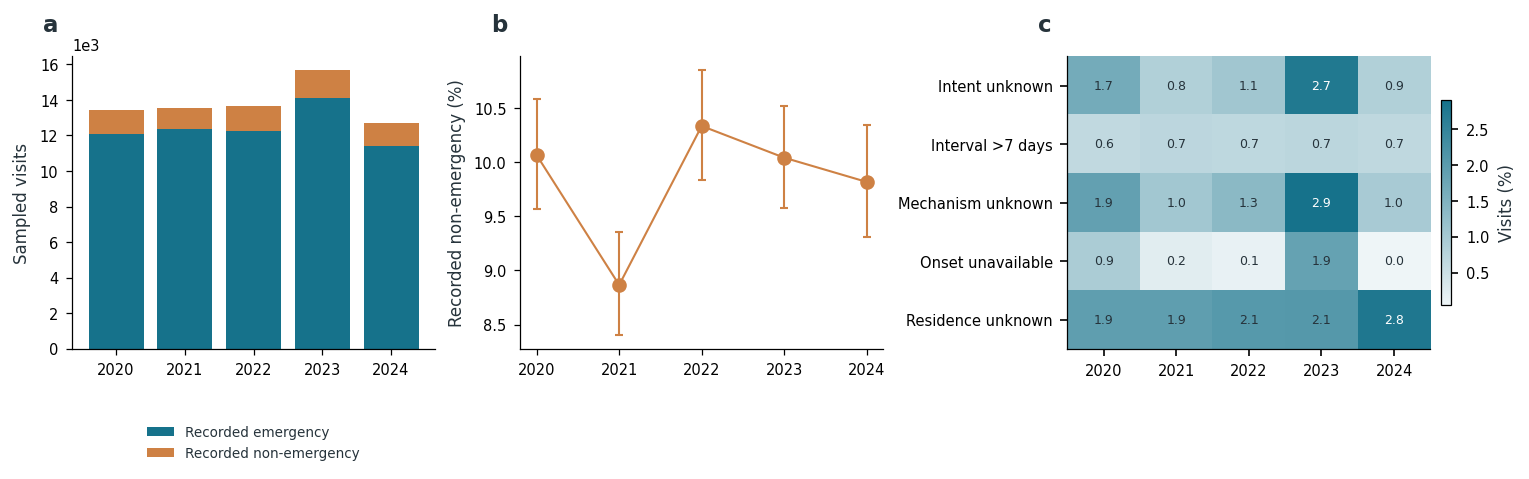

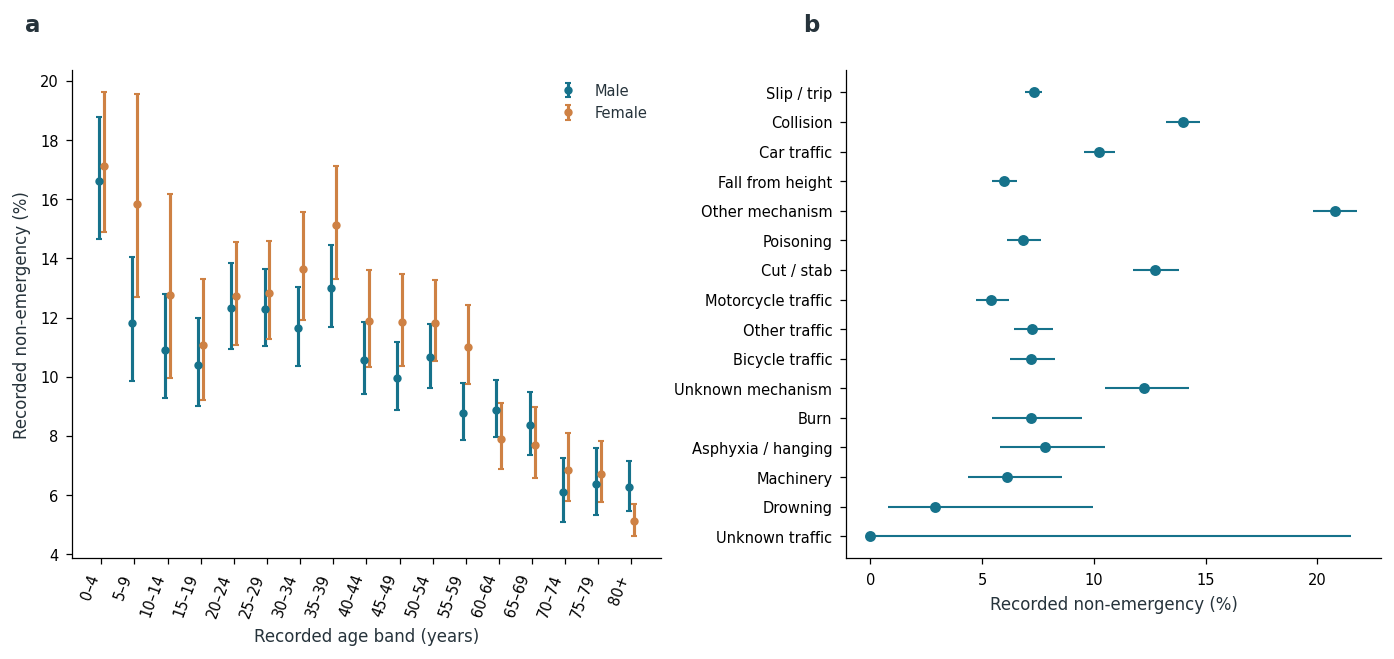

In [4]:
# 04. 공통 분모를 가진 빈도표. 코딩된 N 비율과 사례 수를 함께 반환합니다.
def rates(group):
    t=pd.DataFrame({'group':np.asarray(group).astype(str),'positive':y}).groupby('group',sort=False).positive.agg(['size','sum']).reset_index()
    t.columns=['group','n','N_count']
    t['N_fraction']=t.N_count/t.n
    t['CI_low'],t['CI_high']=wilson(t.N_count,t.n)
    return t
annual=rates(years).sort_values('group')
record('04_annual',annual,'연도별 표본과 기록된 비응급 비율')
long=[]
for col in ['Age band','Sex','Injury mechanism','Intent','Arrival route','Transport','Residence','Center tier']:
    tab=rates(F[col]);tab.insert(0,'variable',col);long.append(tab)
table1=pd.concat(long,ignore_index=True)
record('05_table1',table1,'전체 표본의 범주별 분모와 관측비율',show=False)
missing=[]
for year in sorted(np.unique(years)):
    ix=years==year
    for label,flag in [('Onset unavailable',delay.isna()),('Interval >7 days',delay.gt(10080)),
                       ('Residence unknown',cohort.PTMIPTAR.eq(99)),('Intent unknown',cohort.PTMIARCF.eq(9)),
                       ('Mechanism unknown',cohort.PTMIARCS.eq(99))]:
        missing.append({'year':year,'item':label,'n':int(ix.sum()),'flagged':int(flag[ix].sum()),'fraction':float(flag[ix].mean())})
missing=pd.DataFrame(missing)
record('06_semantic_missingness',missing,'미상 코드와 긴 시간 간격',show=False)
fig,axs=plt.subplots(1,3,figsize=(10.1,3.1),layout='constrained')
ax=axs[0];yy=annual.group
ax.bar(yy,annual.n-annual.N_count,color=BLUE,label='Recorded emergency')
ax.bar(yy,annual.N_count,bottom=annual.n-annual.N_count,color=ORANGE,label='Recorded non-emergency')
ax.set_ylabel('Sampled visits');ax.ticklabel_format(axis='y',style='sci',scilimits=(3,3));style(ax);panel(ax,'a')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.22),fontsize=6.5)
ax=axs[1];xx=np.arange(len(annual))
ax.errorbar(xx,100*annual.N_fraction,yerr=100*np.vstack([annual.N_fraction-annual.CI_low,annual.CI_high-annual.N_fraction]),fmt='o-',color=ORANGE,lw=1,capsize=2)
ax.set_xticks(xx,annual.group);ax.set_ylabel('Recorded non-emergency (%)');style(ax);panel(ax,'b')
ax=axs[2];mat=missing.pivot(index='item',columns='year',values='fraction')
im=ax.imshow(100*mat.to_numpy(),aspect='auto',cmap=CMAP)
ax.set_xticks(range(5),mat.columns);ax.set_yticks(range(len(mat)),mat.index)
for a,b in np.ndindex(mat.shape):
    v=100*mat.iloc[a,b];ax.text(b,a,f'{v:.1f}',ha='center',va='center',fontsize=6,color='white' if v>2.5 else '#26333b')
fig.colorbar(im,ax=ax,shrink=.7,pad=.03,label='Visits (%)');panel(ax,'c')
figure('Figure_01_cohort',fig,'Figure 1. Sample composition and recording quality, 2020–2024. Wilson 95% intervals summarize visit-level proportions. Counts refer to the provided sample. Heatmap cells show percentages.')

# 연령 구간은 수치의 순서를 유지합니다. 성별 비교의 분모가 다르므로 비율과 구간을 그립니다.
sex_age=pd.DataFrame({'age':F['Age band'],'sex':F.Sex,'label':y}).groupby(['age','sex']).label.agg(['size','sum']).reset_index()
sex_age['rate']=sex_age['sum']/sex_age['size']
sex_age['low'],sex_age['high']=wilson(sex_age['sum'],sex_age['size'])
record('07_age_sex',sex_age,'연령·성별 구성',show=False)
mech=table1[table1.variable.eq('Injury mechanism')].sort_values('n',ascending=False)
fig,axs=plt.subplots(1,2,figsize=(9.2,4.3),layout='constrained',gridspec_kw={'width_ratios':[1.1,1]})
ax=axs[0]
for j,sex in enumerate(['Male','Female']):
    z=sex_age[sex_age.sex.eq(sex)].set_index('age').reindex(age_names)
    ax.errorbar(np.arange(17)+(j-.5)*.15,100*z.rate,yerr=100*np.vstack([z.rate-z.low,z.high-z.rate]),fmt='o',ms=3,capsize=1.5,color=COLORS[j],label=sex)
ax.set_xticks(np.arange(17),age_names,rotation=70,ha='right');ax.set_ylabel('Recorded non-emergency (%)');ax.set_xlabel('Recorded age band (years)');ax.legend();style(ax);panel(ax,'a')
ax=axs[1];z=mech.iloc[::-1];pos=np.arange(len(z))
ax.hlines(pos,100*z.CI_low,100*z.CI_high,color=BLUE,lw=1);ax.scatter(100*z.N_fraction,pos,s=18,color=BLUE)
ax.set_yticks(pos,z.group);ax.set_xlabel('Recorded non-emergency (%)');style(ax,'x');panel(ax,'b')
figure('Figure_02_case_mix',fig,'Figure 2. Recorded non-emergency proportions by age, sex and injury mechanism. Error bars are Wilson 95% intervals. Denominators are provided in the matching CSV tables.')

## 4. 발병–도착 간격과 시간 기록의 특징
- 중앙값·사분위수·상위 백분위수를 연도별로 제공합니다. 전체 유효 간격과 7일 이내 구간의 분모를 모두 남깁니다.
- 발병 분(minute)이 00·30 등에 몰리는지 확인합니다. 기록된 시각의 정밀도가 서로 다를 가능성을 탐색하는 그림입니다.
- 분포 그림에서 로그 눈금을 사용해 짧은 간격과 긴 간격을 함께 표시합니다. 긴 간격을 임의로 정상 값으로 바꾸지 않습니다.

,year,visits,valid_interval,within_7d,median_min,q25_min,q75_min,p95_min,max_min
0,2020,13431,13306,13220,55.0,33.0,109.75,1434.0,525600.0
1,2021,13546,13516,13419,60.0,37.0,123.00,1509.5,525636.0
2,2022,13661,13643,13551,60.0,39.0,120.00,1436.0,88015.0
3,2023,15673,15382,15269,57.0,36.0,112.00,1440.0,259200.0
4,2024,12680,12674,12590,58.0,37.0,119.00,1440.0,87880.0


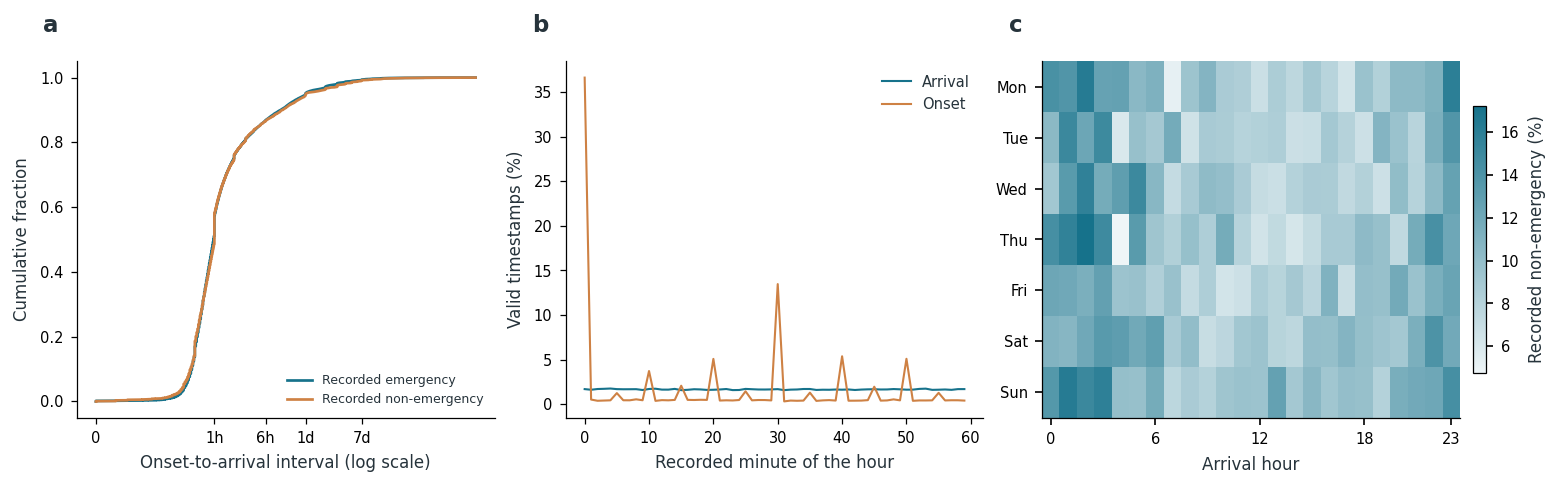

In [5]:
# 05. 결과표에는 긴 꼬리를 보존합니다. 모델 입력의 상한과 원자료 통계를 구분합니다.
rows=[]
for year in sorted(np.unique(years)):
    d=delay[years==year];ok=d[d.ge(0)]
    rows.append({'year':year,'visits':len(d),'valid_interval':len(ok),'within_7d':int(ok.le(10080).sum()),
                 'median_min':ok.median(),'q25_min':ok.quantile(.25),'q75_min':ok.quantile(.75),
                 'p95_min':ok.quantile(.95),'max_min':ok.max()})
interval_table=pd.DataFrame(rows)
record('08_onset_intervals',interval_table,'발병–도착 시간 분포')
clock=pd.DataFrame({'arrival_hour':dates.dt.hour,'weekday':dates.dt.dayofweek,'positive':y})
hour_week=clock.groupby(['weekday','arrival_hour']).positive.agg(['size','sum']).reset_index()
hour_week['rate']=hour_week['sum']/hour_week['size']
record('09_arrival_clock',hour_week,'요일·내원시각',show=False)
fig,axs=plt.subplots(1,3,figsize=(10.3,3.15),layout='constrained')
ax=axs[0]
for k,label in [(0,'Recorded emergency'),(1,'Recorded non-emergency')]:
    values=np.sort(delay[(y==k)&delay.ge(0)].to_numpy())
    ax.plot(np.log1p(values),np.arange(1,len(values)+1)/len(values),color=COLORS[k],lw=1.3,label=label)
ticks=np.array([0,60,360,1440,10080]);ax.set_xticks(np.log1p(ticks),['0','1h','6h','1d','7d'])
ax.set_xlabel('Onset-to-arrival interval (log scale)');ax.set_ylabel('Cumulative fraction');ax.legend(loc='lower right',fontsize=6);style(ax);panel(ax,'a')
ax=axs[1]
parsed_on=onset.loc[valid].reset_index(drop=True)
for label,series,color in [('Arrival',dates,BLUE),('Onset',parsed_on,ORANGE)]:
    counts=series.dt.minute.value_counts(normalize=True).reindex(range(60),fill_value=0)
    ax.plot(counts.index,counts.values*100,color=color,lw=1,label=label)
ax.set_xlabel('Recorded minute of the hour');ax.set_ylabel('Valid timestamps (%)');ax.legend();style(ax);panel(ax,'b')
ax=axs[2];matrix=hour_week.pivot(index='weekday',columns='arrival_hour',values='rate')
im=ax.imshow(100*matrix,cmap=CMAP,aspect='auto');ax.set_yticks(range(7),['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
ax.set_xticks([0,6,12,18,23]);ax.set_xlabel('Arrival hour');fig.colorbar(im,ax=ax,shrink=.75,pad=.03,label='Recorded non-emergency (%)');panel(ax,'c')
figure('Figure_03_time_records',fig,'Figure 3. Onset-to-arrival intervals, timestamp heaping and weekly arrival patterns. The empirical cumulative distributions include all non-negative parsed intervals. The heatmap is descriptive within the selected sample.')

## 5. 미래 연도를 남겨 두고 모델을 비교합니다
- **시간 분할** · 2020–2022년으로 후보를 학습하고, 2023년 1–6월의 Brier score로 각 알고리즘 설정을 선택합니다. 선택된 설정으로 2023년 6월까지 다시 학습합니다. 2023년 7–12월은 확률 보정과 임계값 결정에 사용하고 **2024년을 최종 시험셋**으로 유지합니다.
- **다섯 방법** · 학습 표본의 양성 비율 기준선, 로지스틱 회귀, Extra Trees, 히스토그램 그래디언트 부스팅, CatBoost. 비응급 기록의 비율이 낮아 AP·AUROC·Brier·로그손실을 함께 보고합니다. 정확도만으로 모델을 평가하지 않습니다.
- **동일 비교 조건** · 주 비교는 같은 변수와 시간 분할을 사용합니다. 원핫 인코딩·수치 대체·스케일링은 훈련자료에서 적합합니다. 후보는 알고리즘별 두 개로 제한해 기본 Colab CPU에서도 실행 가능하게 했습니다.
- **주 분석 변수** · 연령·성별·손상기전·의도성·이송수단·내원경로·거주지역·달력·발병 간격. 증상 코드와 기관 종별은 추가 분석에서 평가합니다. 기록 시점이 완전히 확인된 전향적 위험 예측으로 해석하려면 별도의 시간 정보가 필요합니다.

In [6]:
# 06. 동일 일자의 기록은 같은 분할에 들어갑니다. 연도는 예측변수에 넣지 않습니다.
train=np.flatnonzero(dates.lt('2023-01-01'))
tune=np.flatnonzero(dates.ge('2023-01-01') & dates.lt('2023-07-01'))
fit_ids=np.r_[train,tune]
cal=np.flatnonzero(dates.ge('2023-07-01') & dates.lt('2024-01-01'))
test=np.flatnonzero(dates.ge('2024-01-01') & dates.lt('2025-01-01'))
assert len(set(np.r_[train,tune,cal,test]))==len(F)
assert days.iloc[fit_ids].max()<days.iloc[cal].min()<days.iloc[test].min()
split_rows=[]
for name,idx in [('Candidate training',train),('Setting selection',tune),('Calibration',cal),('Final test',test)]:
    assert len(np.unique(y[idx]))==2
    split_rows.append({'partition':name,'start':str(days.iloc[idx].min().date()),'end':str(days.iloc[idx].max().date()),
                      'visits':len(idx),'recorded_N':int(y[idx].sum()),'fraction_N':y[idx].mean(),'days':days.iloc[idx].nunique()})
record('10_time_split',pd.DataFrame(split_rows),'시간 순서 분할')
RUN['split']={r['partition']:r for r in split_rows}

# 각 알고리즘에서 훈련 fold의 전처리와 학습을 하나의 객체로 보관합니다.
def model_factory(name,setting,columns):
    cats=[c for c in columns if c in CAT]
    nums=[c for c in columns if c not in CAT]
    if name=='CatBoost':
        return CatBoostClassifier(iterations=250,depth=setting,learning_rate=.06,loss_function='Logloss',
           random_seed=SEED,l2_leaf_reg=5,thread_count=N_THREADS,verbose=False,allow_writing_files=False,
           cat_features=cats)
    numeric=make_pipeline(SimpleImputer(strategy='median'),StandardScaler())
    categorical=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
    prep=ColumnTransformer([('categorical',categorical,cats),('numeric',numeric,nums)],remainder='drop')
    estimators={
      'Prior':DummyClassifier(strategy='prior'),
      'Logistic':LogisticRegression(C=setting if setting else 1,max_iter=1000,solver='lbfgs'),
      'Extra Trees':ExtraTreesClassifier(n_estimators=180,min_samples_leaf=setting if setting else 5,
                                        max_features=.8,n_jobs=N_THREADS,random_state=SEED),
      'HistGradientBoost':HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=setting if setting else 15,
                  min_samples_leaf=30,l2_regularization=3,early_stopping=False,random_state=SEED)}
    return Pipeline([('preprocess',prep),('model',estimators[name])])

choices={'Prior':[None],'Logistic':[.1,1.0],'Extra Trees':[5,15],'HistGradientBoost':[15,31],'CatBoost':[4,6]}
selected={};validation=[]
for name,values in choices.items():
    for value in values:
        model=model_factory(name,value,CORE).fit(F.iloc[train][CORE],y[train])
        prob=model.predict_proba(F.iloc[tune][CORE])[:,1]
        validation.append({'model':name,'setting':str(value),'value':value,'Brier':brier_score_loss(y[tune],prob),
                           'AP':average_precision_score(y[tune],prob)})
    available=[v for v in validation if v['model']==name]
    selected[name]=min(available,key=lambda v:v['Brier'])['value']
    print(name,'설정 선택 완료',selected[name])
record('11_validation',pd.DataFrame(validation).drop(columns='value'),'2023년 상반기 설정 선택',show=False)

# 보정은 별도 시기의 log-odds 하나를 입력으로 하는 sigmoid 변환입니다.
def margin(est,data):
    if isinstance(est,CatBoostClassifier):
        return np.asarray(est.predict(data,prediction_type='RawFormulaVal'))
    return logit(np.clip(est.predict_proba(data)[:,1],1e-7,1-1e-7))

def fit_calibrator(est,columns,cal_ids,frame=F):
    m=margin(est,frame.iloc[cal_ids][columns])
    return LogisticRegression(C=1000,max_iter=500).fit(m[:,None],y[cal_ids])

def calibrated(est,calibrator,data):
    return calibrator.predict_proba(margin(est,data)[:,None])[:,1]

def cutoff(labels,prob):
    fpr,tpr,thresholds=roc_curve(labels,prob)
    candidates=np.flatnonzero(np.isfinite(thresholds))
    return float(thresholds[candidates[np.argmax((tpr-fpr)[candidates])]])

def scores(labels,prob,threshold=None):
    result={'AP':average_precision_score(labels,prob),'AUROC':roc_auc_score(labels,prob),
            'Brier':brier_score_loss(labels,prob),'Log_loss':log_loss(labels,prob,labels=[0,1])}
    # 임계값을 보정셋에서 지정한 비교에만 민감도·특이도를 추가합니다.
    if threshold is None:
        return result
    tn,fp,fn,tp=confusion_matrix(labels,prob>=threshold,labels=[0,1]).ravel()
    divide=lambda a,b:float(a/b) if b else np.nan
    result.update({'Sensitivity':divide(tp,tp+fn),'Specificity':divide(tn,tn+fp),'PPV':divide(tp,tp+fp),
       'Balanced_acc':.5*(divide(tp,tp+fn)+divide(tn,tn+fp)),
       'Flagged_fraction':float(np.mean(prob>=threshold))})
    return result

models={};calibrators={};pred={};raw_pred={};thresholds={};performance=[]
for name in choices:
    t=perf_counter()
    est=model_factory(name,selected[name],CORE).fit(F.iloc[fit_ids][CORE],y[fit_ids])
    calibrator=fit_calibrator(est,CORE,cal)
    threshold=cutoff(y[cal],calibrated(est,calibrator,F.iloc[cal][CORE]))
    p=calibrated(est,calibrator,F.iloc[test][CORE])
    models[name]=est;calibrators[name]=calibrator;thresholds[name]=threshold
    pred[name]=p;raw_pred[name]=est.predict_proba(F.iloc[test][CORE])[:,1]
    performance.append({'model':name,**scores(y[test],p,threshold),'threshold_2023':threshold,
                        'fit_and_calibration_s':perf_counter()-t})
performance=pd.DataFrame(performance)
record('12_test_models',performance,'2024년 독립 시험 성능')
RUN['settings']=selected
RUN['feature_sets']={'primary':CORE,'context':CONTEXT,'onset':TIMING}

Prior 설정 선택 완료 None
Logistic 설정 선택 완료 0.1
Extra Trees 설정 선택 완료 15
HistGradientBoost 설정 선택 완료 15
CatBoost 설정 선택 완료 4


,partition,start,end,visits,recorded_N,fraction_N,days
0,Candidate training,2020-01-01,2022-12-31,40638,3965,0.0976,1096
1,Setting selection,2023-01-01,2023-06-30,7395,779,0.1053,181
2,Calibration,2023-07-01,2023-12-31,8278,795,0.0960,184
3,Final test,2024-01-01,2024-12-31,12680,1245,0.0982,366


,model,AP,AUROC,Brier,Log_loss,Sensitivity,Specificity,PPV,Balanced_acc,Flagged_fraction,threshold_2023,fit_and_calibration_s
0,Prior,0.0982,0.5000,0.0886,0.3211,1.0000,0.0000,0.0982,0.5000,1.0000,0.0960,0.2834
1,Logistic,0.1942,0.6735,0.0852,0.3037,0.5936,0.6542,0.1575,0.6239,0.3701,0.0951,0.4857
2,Extra Trees,0.1902,0.6501,0.0854,0.3073,0.4683,0.7195,0.1538,0.5939,0.2990,0.1145,28.2778
3,HistGradientBoost,0.1995,0.6757,0.0848,0.3029,0.6402,0.6159,0.1536,0.6280,0.4092,0.0873,2.2864
4,CatBoost,0.2037,0.6748,0.0849,0.3031,0.6490,0.5983,0.1496,0.6236,0.4260,0.0853,8.9652


## 6. 같은 시험 일자를 재추출해 불확실성을 계산합니다
- **독립 시험 단위**는 2024년 내원 기록입니다. 동일 일자의 공통 영향을 고려해 **내원일자를 블록으로** 재추출하며 같은 표본을 모든 모델에 적용합니다. 일자 블록의 교환 가능성을 가정합니다.
- 개인·병원 식별자가 없어 병원 군집이나 반복환자 의존성까지 보정한 구간은 계산할 수 없습니다. 구간은 고정된 학습자료·모델에 조건부이며, 모델 재학습 변동까지 포함하지 않습니다.
- CatBoost와 나머지 네 방법을 주 대조로 두고 Brier 차이의 95% 구간·양측 일자 부호 무작위화 p값·Holm 보정을 함께 제공합니다. AP 차이의 대응 부트스트랩 구간도 저장합니다. 비유의 결과만으로 두 방법의 동등성을 선언하지 않습니다.

,comparator,Brier_difference,Brier_CI_low,Brier_CI_high,AP_difference,AP_CI_low,AP_CI_high,p_raw,p_Holm
0,Prior,-0.0037,-0.0048,-0.0026,0.1055,0.0892,0.1272,0.0005,0.0020
1,Logistic,-0.0003,-0.0008,0.0002,0.0094,-0.0001,0.0211,0.2060,0.4120
2,Extra Trees,-0.0005,-0.0011,0.0000,0.0135,0.0028,0.0257,0.0635,0.1905
3,HistGradientBoost,0.0000,-0.0003,0.0003,0.0042,-0.0024,0.0101,0.8545,0.8545


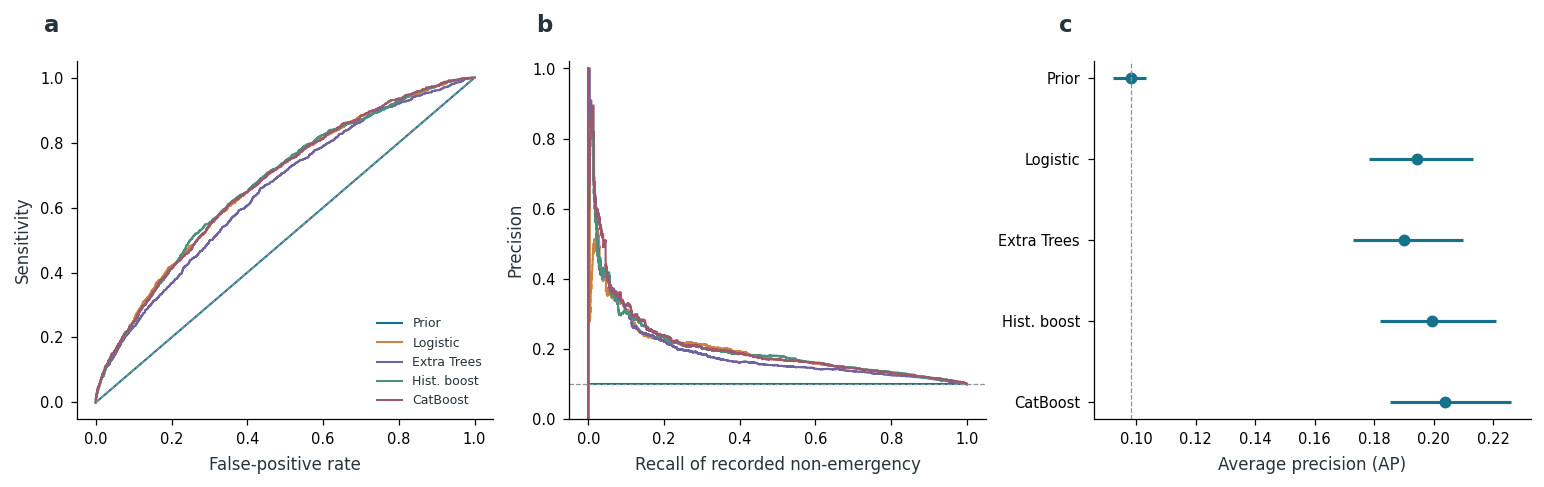

In [7]:
# 07. 같은 점수를 가진 관측치를 묶어 가중 AP/AUROC를 계산합니다. 반복 재학습은 수행하지 않습니다.
def metric_engine(labels,prob):
    labels=np.asarray(labels,dtype=float);prob=np.asarray(prob)
    order=np.argsort(-prob,kind='stable')
    truth=labels[order]
    ends=np.r_[np.flatnonzero(np.diff(prob[order])!=0),len(prob)-1]
    def evaluate(weights):
        w=np.asarray(weights,dtype=float)
        ws=w[order]
        tp=np.cumsum(ws*truth)[ends]
        fp=np.cumsum(ws*(1-truth))[ends]
        positives=tp[-1];negatives=fp[-1]
        if min(positives,negatives)<=0:
            return np.array([np.nan,np.nan,np.nan])
        recall=tp/positives
        precision=np.divide(tp,tp+fp,out=np.zeros_like(tp),where=tp+fp>0)
        ap=np.sum(np.diff(np.r_[0,recall])*precision)
        fpr=fp/negatives
        auc=np.sum(np.diff(np.r_[0,fpr])*(recall+np.r_[0,recall[:-1]])/2)
        brier=np.sum(w*(prob-labels)**2)/w.sum()
        return np.array([ap,auc,brier])
    # 가중 구현이 sklearn 정의와 맞는지 해당 데이터에서 확인합니다.
    w=np.random.default_rng(SEED).uniform(.2,2,len(labels))
    actual=evaluate(w)
    expected=[average_precision_score(labels,prob,sample_weight=w),roc_auc_score(labels,prob,sample_weight=w),
              np.average((prob-labels)**2,weights=w)]
    assert np.allclose(actual,expected,rtol=1e-9,atol=1e-11)
    return evaluate

blocks,day_names=pd.factorize(days.iloc[test],sort=True)
n_days=len(day_names)
rng=np.random.default_rng(SEED+10)
block_draws=rng.multinomial(n_days,np.repeat(1/n_days,n_days),size=BOOTSTRAPS)
engines={name:metric_engine(y[test],p) for name,p in pred.items()}
boot={name:np.asarray([engine(draw[blocks]) for draw in block_draws]) for name,engine in engines.items()}
intervals=[]
for name in pred:
    for j,measure in enumerate(['AP','AUROC','Brier']):
        lo,hi=np.nanquantile(boot[name][:,j],[.025,.975])
        intervals.append({'model':name,'metric':measure,'estimate':float(performance.set_index('model').loc[name,measure]),
                          'CI_low':lo,'CI_high':hi,'resamples':BOOTSTRAPS,'day_blocks':n_days})
intervals=pd.DataFrame(intervals)
record('13_model_intervals',intervals,'일자 블록 95% 구간',show=False)

def holm(values):
    p=np.asarray(values);order=np.argsort(p);out=np.empty_like(p)
    out[order]=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))
    return out

# 네 대조에서 같은 무작위 부호 행렬을 쓰면 재현과 대응 구조가 유지됩니다.
signs=np.random.default_rng(SEED+11).choice([-1,1],size=(PERMUTATIONS,n_days))
comparisons=[]
for name in [v for v in pred if v!='CatBoost']:
    delta=(pred['CatBoost']-y[test])**2-(pred[name]-y[test])**2
    sums=np.bincount(blocks,weights=delta,minlength=n_days)
    observed=delta.mean()
    random_means=signs@sums/len(test)
    pval=(1+np.sum(abs(random_means)>=abs(observed)-1e-14))/(PERMUTATIONS+1)
    lo,hi=np.quantile(boot['CatBoost'][:,2]-boot[name][:,2],[.025,.975])
    apl,aph=np.quantile(boot['CatBoost'][:,0]-boot[name][:,0],[.025,.975])
    comparisons.append({'comparator':name,'Brier_difference':observed,'Brier_CI_low':lo,'Brier_CI_high':hi,
       'AP_difference':performance.set_index('model').loc['CatBoost','AP']-performance.set_index('model').loc[name,'AP'],
       'AP_CI_low':apl,'AP_CI_high':aph,'p_raw':pval})
comparisons=pd.DataFrame(comparisons);comparisons['p_Holm']=holm(comparisons.p_raw)
record('14_paired_tests',comparisons,'CatBoost − 비교 모델의 대응검정')

# ROC와 PR을 같이 보며, AP의 무정보 기준은 이번 시험셋의 N 비율입니다.
fig,axs=plt.subplots(1,3,figsize=(10.2,3.15),layout='constrained',gridspec_kw={'width_ratios':[1,1,1.05]})
for i,name in enumerate(pred):
    fpr,tpr,_=roc_curve(y[test],pred[name]);precision,recall,_=precision_recall_curve(y[test],pred[name])
    label=name.replace('HistGradientBoost','Hist. boost')
    axs[0].plot(fpr,tpr,color=COLORS[i],label=label,lw=1)
    axs[1].step(recall,precision,where='post',color=COLORS[i],lw=1)
axs[0].plot([0,1],[0,1],'--',lw=.6,color='#89949b')
axs[0].set(xlabel='False-positive rate',ylabel='Sensitivity');axs[0].legend(loc='lower right',fontsize=6)
axs[1].axhline(y[test].mean(),ls='--',color='#89949b',lw=.6)
axs[1].set(xlabel='Recall of recorded non-emergency',ylabel='Precision',ylim=(0,1.02))
z=intervals[intervals.metric.eq('AP')].iloc[::-1];pos=np.arange(len(z))
axs[2].hlines(pos,z.CI_low,z.CI_high,color=BLUE);axs[2].scatter(z.estimate,pos,color=BLUE,s=22)
axs[2].set_yticks(pos,z.model.str.replace('HistGradientBoost','Hist. boost'));axs[2].set_xlabel('Average precision (AP)')
axs[2].axvline(y[test].mean(),ls='--',lw=.6,color='#89949b')
for ax,letter in zip(axs,'abc'):style(ax);panel(ax,letter)
figure('Figure_04_prediction',fig,'Figure 4. Held-out 2024 discrimination. The precision-recall reference is the fraction recorded as non-emergency. AP intervals use paired resampling of arrival dates. Predictors and preprocessing are fitted before the calibration and test periods.')

## 7. 확률 보정과 검토 업무량을 봅니다
- 분류기의 점수가 높아도 예측확률이 실제 비율과 맞는지는 별개입니다. CatBoost의 보정 전후 Brier와 확률 구간별 관측비율을 비교합니다.
- 임계값은 2023년 하반기에서 균형정확도를 최대화하도록 정했습니다. 2024년의 민감도·특이도·양성예측도는 이 고정 임계값의 결과입니다.
- 상위 점수 기록을 5~50% 확인할 때 포함되는 비응급 기록의 비율을 보여줍니다. 경계에서 점수가 같으면 동점 집단에서 균일하게 선택할 때의 기대 포함 건수를 계산합니다. 자료 점검 업무의 우선순위 분석이며 의료서비스 제공 여부를 결정하는 규칙으로 검증된 것은 아닙니다.

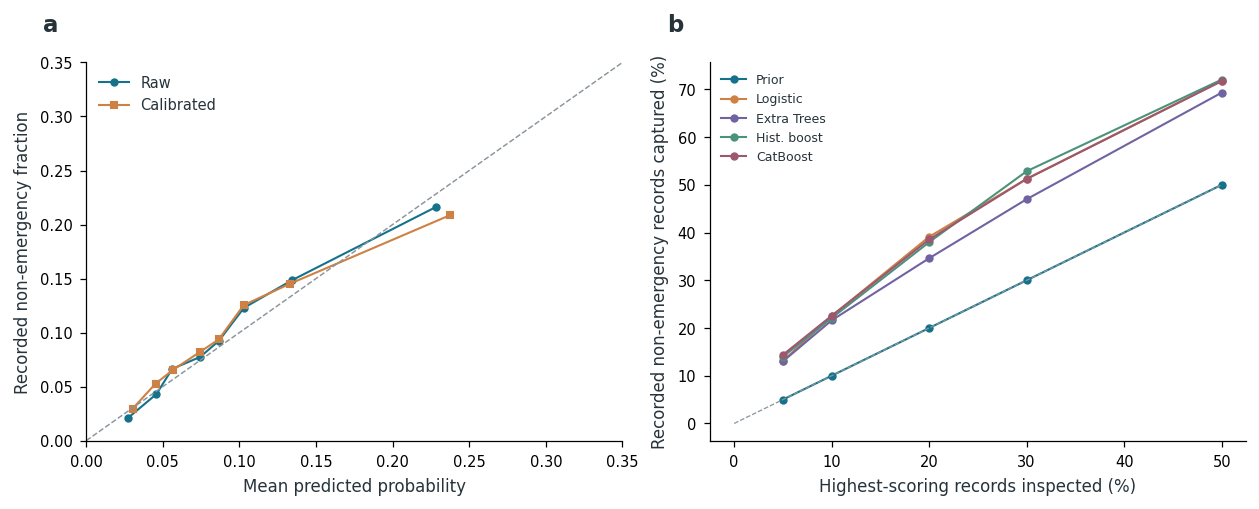

In [8]:
# 08. 보정곡선의 bin 경계는 2023년 보정셋 예측값의 분위수로 고정합니다.
cal_scores=calibrated(models['CatBoost'],calibrators['CatBoost'],F.iloc[cal][CORE])
bin_edges=np.unique(np.r_[0,np.quantile(cal_scores,np.linspace(0,1,9))[1:-1],1])
calibration_rows=[]
for name,p in [('Raw CatBoost',raw_pred['CatBoost']),('Calibrated CatBoost',pred['CatBoost'])]:
    bins=np.clip(np.digitize(p,bin_edges)-1,0,len(bin_edges)-2)
    for b in np.unique(bins):
        mask=bins==b;k=y[test][mask].sum();n=int(mask.sum());lo,hi=wilson(k,n)
        calibration_rows.append({'model':name,'bin':int(b),'n':n,'mean_prediction':p[mask].mean(),
                      'observed_fraction':k/n,'CI_low':lo,'CI_high':hi})
calibration=pd.DataFrame(calibration_rows)
record('15_calibration_bins',calibration,'2024년 확률 보정',show=False)
workload=[]
for name,p in pred.items():
    order=np.argsort(-p,kind='stable')
    for fraction in [.05,.10,.20,.30,.50]:
        n=int(np.ceil(len(test)*fraction))
        boundary=p[order[n-1]]
        higher=p>boundary
        tied=p==boundary
        fraction_of_ties=(n-int(higher.sum()))/int(tied.sum())
        captured=float(y[test][higher].sum()+fraction_of_ties*y[test][tied].sum())
        workload.append({'model':name,'review_fraction':n/len(test),'reviewed':n,
                         'expected_N_captured':captured,'capture_fraction':captured/y[test].sum(),
                         'precision':captured/n,'lift':(captured/n)/y[test].mean()})
workload=pd.DataFrame(workload)
record('16_review_workload',workload,'점수순 자료 검토의 업무량',show=False)
calibration_compare=pd.DataFrame([{'model':tag,**scores(y[test],p)}
             for tag,p in [('Raw CatBoost',raw_pred['CatBoost']),('Calibrated CatBoost',pred['CatBoost'])]])
record('17_calibration_effect',calibration_compare,'확률 보정 전후',show=False)
fig,axs=plt.subplots(1,2,figsize=(8.3,3.3),layout='constrained')
ax=axs[0]
for j,name in enumerate(calibration.model.unique()):
    z=calibration[calibration.model.eq(name)]
    ax.plot(z.mean_prediction,z.observed_fraction,marker=['o','s'][j],ms=3,lw=1,color=COLORS[j],label=name.replace(' CatBoost',''))
limit=max(.35,calibration[['mean_prediction','observed_fraction']].max().max()*1.04)
ax.plot([0,limit],[0,limit],ls='--',color='#89949b',lw=.7);ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='Mean predicted probability',ylabel='Recorded non-emergency fraction')
ax.legend();style(ax);panel(ax,'a')
ax=axs[1]
for i,name in enumerate(pred):
    z=workload[workload.model.eq(name)]
    ax.plot(100*z.review_fraction,100*z.capture_fraction,marker='o',ms=3,lw=1,color=COLORS[i],label=name.replace('HistGradientBoost','Hist. boost'))
ax.plot([0,50],[0,50],'--',color='#89949b',lw=.6);ax.set(xlabel='Highest-scoring records inspected (%)',ylabel='Recorded non-emergency records captured (%)')
ax.legend(fontsize=6);style(ax);panel(ax,'b')
figure('Figure_05_calibration_workload',fig,'Figure 5. Probability calibration and record-review yield in 2024. Calibration-bin boundaries come from the 2023 calibration period. Review yield describes ranking the recorded label and does not establish a clinical triage policy.')

## 8. 변수군을 제거하거나 기록 정보를 추가합니다
- **제거 실험** · 발병 간격·시각, 손상기전·의도성, 거주지역을 각각 빼고 모델을 다시 학습합니다.
- **추가 실험** · 기관 종별, 증상 코드, 증상 일련번호를 단계적으로 더합니다. 이 변수들의 실제 입력 완료 시점은 현재 파일에서 확인되지 않으므로 기록 정보에 의존하는 정도를 분석합니다.
- 모든 조건에 같은 CatBoost 깊이·학습 횟수·시간 분할을 적용하고 각 조건의 2023년 하반기 보정기를 다시 적합합니다. 기본 모델과의 차이는 동일한 2024년 일자 재표집으로 평가합니다.
- 주증상 코드 문자열은 뜻을 추측해 합치지 않습니다. 증상 일련번호는 숫자의 크기로 쓰지 않고 범주로 둡니다.

Without onset timing 완료
Without injury / intent 완료
Without residence 완료
Plus center tier 완료
Plus center and complaint 완료
Plus full coding context 완료
Coding context only 완료


,variant,features,AP,AUROC,Brier,Log_loss,Brier_difference_from_core
0,Without onset timing,12,0.2017,0.6732,0.0850,0.3034,0.0001
1,Without injury / intent,13,0.1595,0.6293,0.0867,0.3111,0.0018
2,Without residence,14,0.2053,0.6765,0.0848,0.3027,-0.0001
3,Plus center tier,16,0.2046,0.6749,0.0849,0.3030,0.0000
4,Plus center and complaint,17,0.2252,0.7020,0.0838,0.2976,-0.0011
5,Plus full coding context,18,0.2314,0.7071,0.0836,0.2965,-0.0013
6,Coding context only,3,0.1917,0.6549,0.0854,0.3057,0.0005


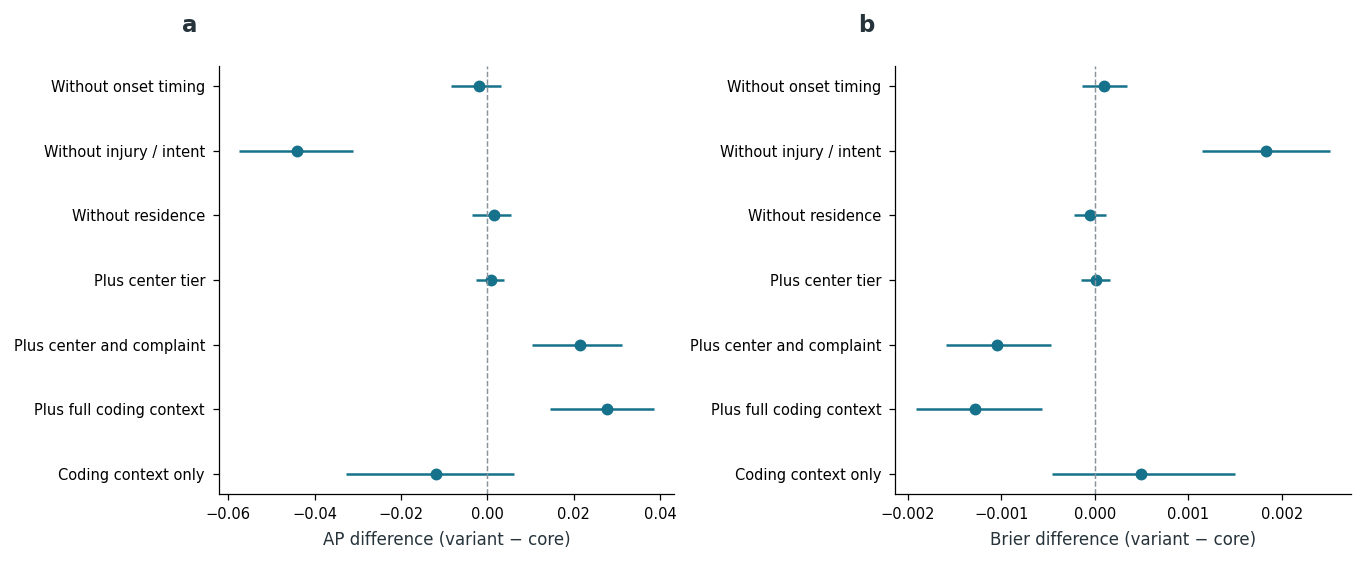

In [9]:
# 09. 특성 중요도 순위만으로 효과를 판단하지 않고, 실제로 모델을 다시 적합합니다.
sets={
 'Without onset timing':[c for c in CORE if c not in TIMING],
 'Without injury / intent':[c for c in CORE if c not in ['Injury mechanism','Intent']],
 'Without residence':[c for c in CORE if c!='Residence'],
 'Plus center tier':CORE+['Center tier'],
 'Plus center and complaint':CORE+['Center tier','Complaint code'],
 'Plus full coding context':CORE+CONTEXT,
 'Coding context only':CONTEXT}
variants={};variant_pred={};variant_rows=[];variant_intervals=[]
for tag,columns in sets.items():
    est=model_factory('CatBoost',selected['CatBoost'],columns).fit(F.iloc[fit_ids][columns],y[fit_ids])
    calibrator=fit_calibrator(est,columns,cal)
    p=calibrated(est,calibrator,F.iloc[test][columns])
    variants[tag]=(est,calibrator,columns)
    variant_pred[tag]=p
    engine=metric_engine(y[test],p)
    bs=np.asarray([engine(draw[blocks]) for draw in block_draws])
    diff=bs-boot['CatBoost']
    for j,key in enumerate(['AP','AUROC','Brier']):
        lo,hi=np.quantile(diff[:,j],[.025,.975])
        variant_intervals.append({'variant':tag,'metric':key,'difference_from_core':engine(np.ones(len(test)))[j]-engines['CatBoost'](np.ones(len(test)))[j],
                                 'CI_low':lo,'CI_high':hi})
    variant_rows.append({'variant':tag,'features':len(columns),**scores(y[test],p),
                         'Brier_difference_from_core':brier_score_loss(y[test],p)-brier_score_loss(y[test],pred['CatBoost'])})
    print(tag,'완료')
variant_rows=pd.DataFrame(variant_rows);variant_intervals=pd.DataFrame(variant_intervals)
record('18_ablations',variant_rows,'변수 제거·추가 후 2024년 성능')
record('19_ablation_intervals',variant_intervals,'어블레이션 − 기본 모델의 대응 구간',show=False)
fig,axs=plt.subplots(1,2,figsize=(9.0,3.65),layout='constrained')
for ax,key,letter in zip(axs,['AP','Brier'],'ab'):
    z=variant_intervals[variant_intervals.metric.eq(key)].iloc[::-1];pos=np.arange(len(z))
    ax.hlines(pos,z.CI_low,z.CI_high,color=BLUE,lw=1.2);ax.scatter(z.difference_from_core,pos,color=BLUE,s=22)
    ax.axvline(0,color='#88939c',ls='--',lw=.7);ax.set_yticks(pos,z.variant)
    ax.set_xlabel(key+' difference (variant − core)');style(ax,'x');panel(ax,letter)
figure('Figure_06_ablation',fig,'Figure 6. Retrained feature-set contrasts using the same chronological design. Positive AP differences and negative Brier differences favor the variant. Intervals use paired arrival-date bootstrap draws. Coding-context additions are retrospective sensitivity analyses.')

## 9. 시간 분할과 미상 시각 처리의 민감도를 확인합니다
- **순차 검증** · 2022·2023·2024년을 각각 시험 연도로 둡니다. 매번 직전 연도 6월까지 학습하고 7–12월로 보정합니다. 세 실험에는 미리 고정한 깊이 4·200회 CatBoost를 사용합니다. 특정 미래 연도의 튜닝 결과를 과거 검증에 가져오지 않습니다.
- **1111 해석** · 발병시각 1111을 11시 11분으로 인정한 데이터로 같은 주 모델을 다시 학습합니다. 바뀐 행 수와 2024년 결과를 비교합니다.
- **기관 종별 전이** · 권역센터와 지역센터 중 한 종별로 학습·보정한 모델을 2024년의 두 종별에 각각 적용합니다. 기관 종별은 병원 식별자가 아니므로, 이 결과는 종별 간 이동에 대한 민감도입니다.

In [10]:
# 10. 연도별 분석은 고정된 설정으로 완전히 재학습합니다.
def fixed_cat(columns,seed=SEED):
    return CatBoostClassifier(iterations=200,depth=4,learning_rate=.06,l2_leaf_reg=5,loss_function='Logloss',
           random_seed=seed,thread_count=N_THREADS,verbose=False,allow_writing_files=False,
           cat_features=[c for c in columns if c in CAT])
rolling=[]
for year in [2022,2023,2024]:
    learn=np.flatnonzero(dates.lt(f'{year-1}-07-01'))
    adjust=np.flatnonzero(dates.ge(f'{year-1}-07-01') & dates.lt(f'{year}-01-01'))
    hold=np.flatnonzero(dates.ge(f'{year}-01-01') & dates.lt(f'{year+1}-01-01'))
    est=fixed_cat(CORE).fit(F.iloc[learn][CORE],y[learn])
    calibrator=fit_calibrator(est,CORE,adjust)
    p=calibrated(est,calibrator,F.iloc[hold][CORE])
    threshold=cutoff(y[adjust],calibrated(est,calibrator,F.iloc[adjust][CORE]))
    rolling.append({'test_year':year,'fit_visits':len(learn),'cal_visits':len(adjust),'test_visits':len(hold),
                    'N_fraction':y[hold].mean(),**scores(y[hold],p,threshold)})
rolling=pd.DataFrame(rolling)
record('20_rolling_years',rolling,'고정 설정의 순차 연도 검증')

# 원자료에 대한 대체 시각 해석을 적용한 뒤, 동일 분할에서 다시 적합합니다.
F_alt=add_onset(F,delay_alt,onset_alt.loc[valid].reset_index(drop=True))
alt_est=model_factory('CatBoost',selected['CatBoost'],CORE).fit(F_alt.iloc[fit_ids][CORE],y[fit_ids])
alt_cal=fit_calibrator(alt_est,CORE,cal,frame=F_alt)
alt_p=calibrated(alt_est,alt_cal,F_alt.iloc[test][CORE])
changed=(F[TIMING].astype(str)!=F_alt[TIMING].astype(str)).any(axis=1)
sentinel_comparison=pd.DataFrame([
 {'interpretation':'1111 as unknown','changed_rows_all':0,'changed_rows_test':0,**scores(y[test],pred['CatBoost'])},
 {'interpretation':'1111 as 11:11','changed_rows_all':int(changed.sum()),'changed_rows_test':int(changed.iloc[test].sum()),**scores(y[test],alt_p)}])
record('21_sentinel_sensitivity',sentinel_comparison,'발병시각 1111의 대체 해석')

# 동일 종별과 다른 종별의 성능을 같은 모델에서 대조합니다. 표본 규모 차이도 남깁니다.
tier_rows=[]
for source_tier in [1,2]:
    learn=fit_ids[cohort.PTMIEMCL.iloc[fit_ids].to_numpy()==source_tier]
    adjust=cal[cohort.PTMIEMCL.iloc[cal].to_numpy()==source_tier]
    est=fixed_cat(CORE).fit(F.iloc[learn][CORE],y[learn])
    calibrator=fit_calibrator(est,CORE,adjust)
    for target_tier in [1,2]:
        hold=test[cohort.PTMIEMCL.iloc[test].to_numpy()==target_tier]
        p=calibrated(est,calibrator,F.iloc[hold][CORE])
        tier_rows.append({'train_tier':source_tier,'test_tier':target_tier,'fit_visits':len(learn),
           'cal_visits':len(adjust),'test_visits':len(hold),'test_N_fraction':y[hold].mean(),**scores(y[hold],p)})
tier_rows=pd.DataFrame(tier_rows)
record('22_tier_transport',tier_rows,'응급기관 종별 간 전이',show=False)

# 같은 데이터에서 모델 난수만 바꾼 민감도입니다. 세 seed를 독립 환자로 간주하지 않습니다.
seed_rows=[{'seed':SEED,**scores(y[test],pred['CatBoost'])}]
for seed in [SEED+1,SEED+2]:
    est=model_factory('CatBoost',selected['CatBoost'],CORE)
    est.set_params(random_seed=seed)
    est.fit(F.iloc[fit_ids][CORE],y[fit_ids])
    calibrator=fit_calibrator(est,CORE,cal)
    p=calibrated(est,calibrator,F.iloc[test][CORE])
    seed_rows.append({'seed':seed,**scores(y[test],p)})
record('23_seed_sensitivity',pd.DataFrame(seed_rows),'난수별 민감도',show=False)

,test_year,fit_visits,cal_visits,test_visits,N_fraction,AP,AUROC,Brier,Log_loss,Sensitivity,Specificity,PPV,Balanced_acc,Flagged_fraction
0,2022,19777,7200,13661,0.1034,0.2102,0.6744,0.0891,0.3159,0.6353,0.6230,0.1626,0.6291,0.4037
1,2023,33176,7462,15673,0.1004,0.2224,0.6746,0.0857,0.3059,0.7065,0.5516,0.1496,0.6290,0.4743
2,2024,48033,8278,12680,0.0982,0.2051,0.6744,0.0849,0.3031,0.6570,0.5881,0.1480,0.6226,0.4360


,interpretation,changed_rows_all,changed_rows_test,AP,AUROC,Brier,Log_loss
0,1111 as unknown,0,0,0.2037,0.6748,0.0849,0.3031
1,1111 as 11:11,15,3,0.2045,0.6756,0.0848,0.3029


## 10. 하위집단의 성능을 분모와 함께 봅니다
- 성별, 넓은 연령대, 거주지역, 기관 종별에 대해 AP·Brier·민감도·특이도와 사례 수를 보고합니다. 비응급 기록이 20건 미만이거나 전체 100건 미만인 집단은 지표를 공란으로 남깁니다.
- AP는 집단별 양성 비율의 영향도 받습니다. 같은 표에 양성 비율을 넣고 Brier도 함께 확인합니다. 집단 간 성능 차이를 곧바로 차별이나 인과효과로 해석하지 않습니다.
- Brier 구간은 해당 집단의 내원일자를 499회 재추출한 기술적 95% 구간입니다. 여러 하위집단 분석은 탐색적으로 보고합니다.

,family,group,n,N_count,N_fraction,AP,AUROC,Brier,Log_loss,Sensitivity,Specificity,PPV,Balanced_acc,Flagged_fraction,Brier_CI_low,Brier_CI_high,status
0,Sex,Male,6823,678,0.0994,0.2056,0.6704,0.0859,0.3064,0.6888,0.5566,0.1463,0.6227,0.4678,0.0809,0.0909,Estimated
1,Sex,Female,5857,567,0.0968,0.2027,0.6804,0.0837,0.2992,0.6014,0.6467,0.1543,0.6241,0.3773,0.0771,0.0899,Estimated
2,Age,65+,4591,305,0.0664,0.1163,0.6418,0.0612,0.2369,0.2820,0.8521,0.1194,0.5670,0.1568,0.0553,0.0678,Estimated
3,Age,40–64,4321,457,0.1058,0.2378,0.6848,0.0895,0.3149,0.6893,0.5450,0.1520,0.6172,0.4798,0.0828,0.0958,Estimated
4,Age,15–39,2804,363,0.1295,0.2304,0.6481,0.1088,0.3708,0.8044,0.4117,0.1690,0.6081,0.6163,0.1009,0.1190,Estimated
5,Age,0–14,964,120,0.1245,0.1939,0.6107,0.1073,0.3681,0.9583,0.0924,0.1305,0.5254,0.9139,0.0927,0.1206,Estimated
6,Residence,Gyeonggi,10563,1053,0.0997,0.2126,0.6792,0.0856,0.3050,0.6439,0.6132,0.1556,0.6286,0.4124,0.0813,0.0898,Estimated
7,Residence,Outside / unknown,2117,192,0.0907,0.1672,0.6569,0.0811,0.2935,0.6771,0.5242,0.1243,0.6006,0.4941,0.0720,0.0902,Estimated
8,Center tier,Regional emergency center,2883,182,0.0631,0.1355,0.6881,0.0583,0.2260,0.6593,0.6438,0.1109,0.6516,0.3753,0.0508,0.0659,Estimated
9,Center tier,Local emergency center,9797,1063,0.1085,0.2195,0.6681,0.0927,0.3258,0.6472,0.5842,0.1593,0.6157,0.4410,0.0883,0.0970,Estimated


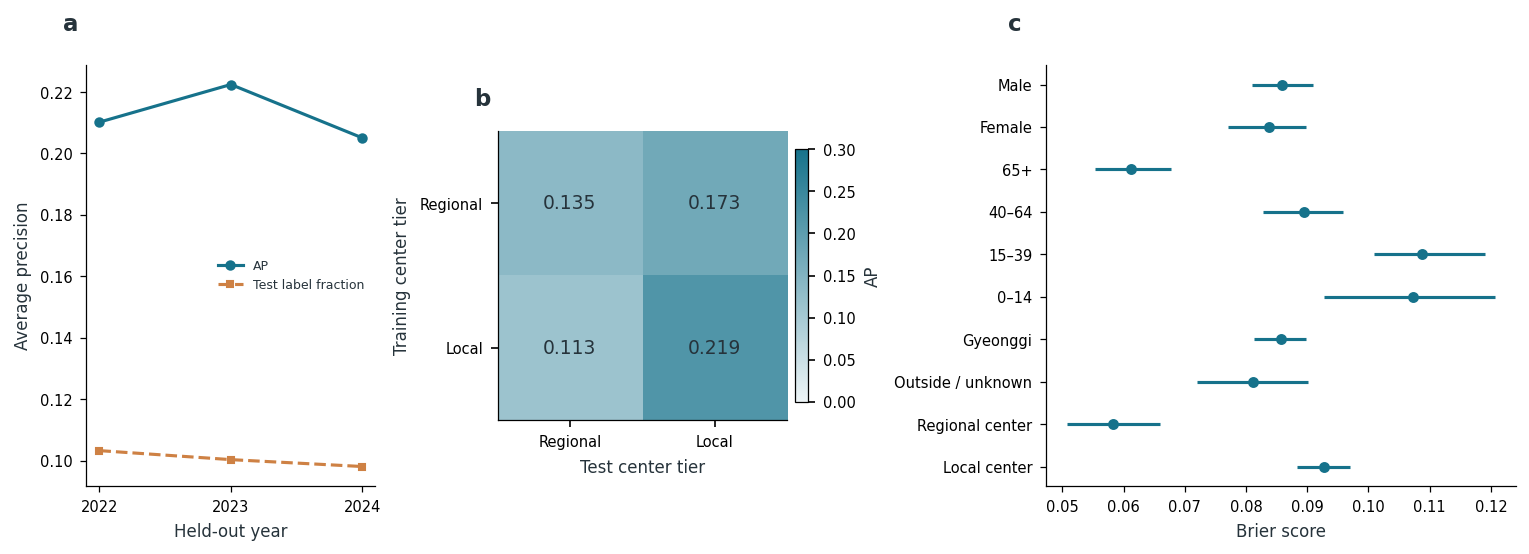

In [11]:
# 11. 개인정보 구간은 원본의 5세 구간을 조합합니다. 15–19세를 임의로 성인/미성년으로 나누지 않습니다.
age_code=cohort.PTMIBRTD.to_numpy()
broad_age=np.select([age_code<=3,age_code<=8,age_code<=13],['0–14','15–39','40–64'],default='65+')
groups={'Sex':F.Sex,'Age':pd.Series(broad_age),'Residence':F.Residence.where(F.Residence.eq('Gyeonggi'),'Outside / unknown'),
        'Center tier':F['Center tier']}
subgroup=[]
for family,series in groups.items():
    for value in pd.unique(series.iloc[test]):
        within=(series.iloc[test].to_numpy()==value)
        yy=y[test][within];pp=pred['CatBoost'][within];n=len(yy);positives=int(yy.sum())
        row={'family':family,'group':value,'n':n,'N_count':positives,'N_fraction':yy.mean()}
        if min(positives,n-positives)>=20 and n>=100:
            row.update(scores(yy,pp,thresholds['CatBoost']))
            group_blocks,_=pd.factorize(days.iloc[test][within],sort=True)
            count=np.bincount(group_blocks);loss=np.bincount(group_blocks,weights=(pp-yy)**2)
            weights=np.random.default_rng(SEED+300).multinomial(len(count),np.repeat(1/len(count),len(count)),size=499)
            losses=(weights@loss)/(weights@count)
            row['Brier_CI_low'],row['Brier_CI_high']=np.quantile(losses,[.025,.975])
            row['status']='Estimated'
        else:
            row['status']='Too few observations for stable subgroup estimates'
        subgroup.append(row)
subgroup=pd.DataFrame(subgroup)
record('24_subgroups',subgroup,'2024년 하위집단의 성능')
fig,axs=plt.subplots(1,3,figsize=(10.1,3.6),layout='constrained',gridspec_kw={'width_ratios':[.8,.8,1.3]})
ax=axs[0];ax.plot(rolling.test_year,rolling.AP,'o-',color=BLUE,ms=4,label='AP')
ax.plot(rolling.test_year,rolling.N_fraction,'s--',color=ORANGE,ms=3,label='Test label fraction')
ax.set_xticks([2022,2023,2024]);ax.set_xlabel('Held-out year');ax.set_ylabel('Average precision');ax.legend(fontsize=6);style(ax);panel(ax,'a')
ax=axs[1];m=tier_rows.pivot(index='train_tier',columns='test_tier',values='AP')
im=ax.imshow(m,cmap=CMAP,vmin=0,vmax=np.ceil(10*m.max().max())/10);ax.set_xticks([0,1],['Regional','Local']);ax.set_yticks([0,1],['Regional','Local'])
ax.set(xlabel='Test center tier',ylabel='Training center tier')
for i,j in np.ndindex(m.shape):ax.text(j,i,f'{m.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9,color='#26333b')
fig.colorbar(im,ax=ax,pad=.03,shrink=.6,label='AP');panel(ax,'b')
ax=axs[2];z=subgroup[subgroup.status.eq('Estimated')].iloc[::-1];pos=np.arange(len(z))
ax.hlines(pos,z.Brier_CI_low,z.Brier_CI_high,color=BLUE);ax.scatter(z.Brier,pos,color=BLUE,s=18)
labels=z.group.replace({'Regional emergency center':'Regional center','Local emergency center':'Local center'})
ax.set_yticks(pos,labels);ax.set_xlabel('Brier score');style(ax,'x');panel(ax,'c')
figure('Figure_07_transport_subgroups',fig,'Figure 7. Fixed-setting rolling-origin discrimination, transport between center tiers and subgroup calibration loss. A center tier is not a hospital identifier. Subgroup Brier intervals resample arrival dates within each group.')

## 11. SHAP을 보정된 모델과 같은 단위로 계산합니다
- CatBoost의 내장 TreeSHAP을 사용합니다. 기본 SHAP의 단위는 원래 모델의 log-odds입니다. 여기서는 2023년 하반기 sigmoid 보정의 기울기와 절편을 적용해 **보정된 log-odds의 설명**을 계산합니다.
- 모든 표시 사례에서 `sigmoid(기준값 + SHAP 합) = 보정된 예측확률`을 자동 확인합니다. SHAP 기여도는 인과효과나 확률의 퍼센트포인트 변화로 해석하지 않습니다.
- 2024년에서 균일하게 뽑은 사례의 전체 중요도·값의 분포·시간 간격 의존성을 그립니다. 숫자의 크기가 없는 범주형 변수는 색으로 임의의 순서를 부여하지 않습니다.
- 선택된 변수군을 함께 섞어 AP와 Brier 변화도 측정합니다. 상관된 변수의 결합을 깨는 검정이므로 중요도는 이 교란 방식에 조건부입니다.

,feature,mean_abs_SHAP_logodds,mean_SHAP_logodds
2,Injury mechanism,0.2588,-0.0142
0,Age band,0.1819,-0.0435
4,Arrival route,0.1235,0.0050
3,Intent,0.0858,-0.0061
12,Log onset interval,0.0750,-0.0022
9,Arrival hour cos,0.0660,-0.0032
5,Transport,0.0345,0.0024
6,Residence,0.0310,0.0053
8,Arrival hour sin,0.0206,-0.0024
1,Sex,0.0206,0.0004


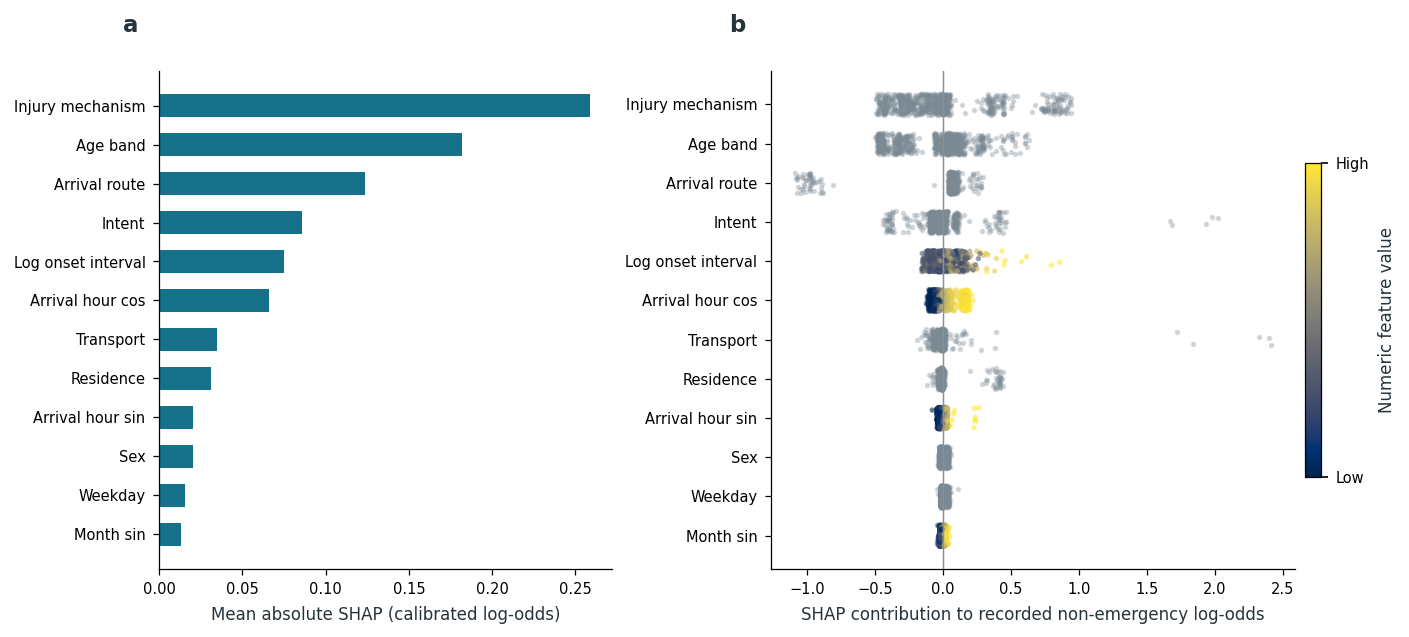

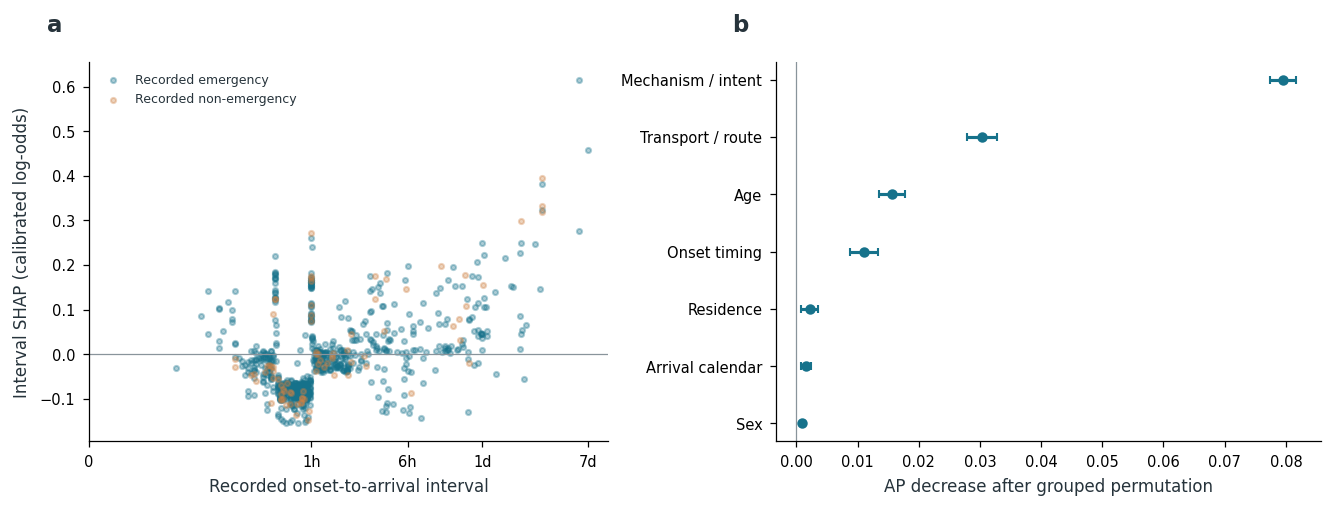

In [12]:
# 12. 범주형 변수와 수치형 변수를 원래 열 그대로 Pool에 전달합니다.
cb=models['CatBoost'];calibrator=calibrators['CatBoost']
rng=np.random.default_rng(SEED+40)
xai_ids=np.sort(rng.choice(test,size=min(SHAP_N,len(test)),replace=False))
a=float(calibrator.coef_[0,0]);b=float(calibrator.intercept_[0])
shap_raw=cb.get_feature_importance(Pool(F.iloc[xai_ids][CORE],cat_features=[c for c in CORE if c in CAT]),
                                 type='ShapValues',thread_count=N_THREADS)
shap_values=shap_raw[:,:-1]*a
bases=shap_raw[:,-1]*a+b
reconstruction=expit(bases+shap_values.sum(axis=1))
expected=calibrated(cb,calibrator,F.iloc[xai_ids][CORE])
max_error=float(np.max(abs(reconstruction-expected)))
assert max_error<1e-8,'SHAP과 보정 확률의 단위 연결을 다시 확인하세요.'
importance=pd.DataFrame({'feature':CORE,'mean_abs_SHAP_logodds':np.mean(abs(shap_values),axis=0),
                         'mean_SHAP_logodds':np.mean(shap_values,axis=0)}).sort_values('mean_abs_SHAP_logodds',ascending=False)
record('25_shap_importance',importance,'보정 log-odds 단위의 SHAP')
RUN['SHAP']={'sample_size':len(xai_ids),'calibration_slope':a,'calibration_intercept':b,'max_probability_reconstruction_error':max_error}

# 변수군 전체에 같은 순열을 적용해 sin/cos와 시간 상태의 조합을 유지합니다.
permutation_groups={'Age':['Age band'],'Sex':['Sex'],'Mechanism / intent':['Injury mechanism','Intent'],
                    'Transport / route':['Transport','Arrival route'],'Residence':['Residence'],
                    'Arrival calendar':['Weekday','Arrival hour sin','Arrival hour cos','Month sin','Month cos'],
                    'Onset timing':TIMING}
perm_rows=[]
baseline_ap=average_precision_score(y[test],pred['CatBoost'])
baseline_brier=brier_score_loss(y[test],pred['CatBoost'])
for label,columns in permutation_groups.items():
    for repeat in range(5):
        copied=F.iloc[test][CORE].copy()
        idx=np.random.default_rng(SEED+70+repeat).permutation(len(test))
        copied.loc[:,columns]=copied[columns].iloc[idx].to_numpy()
        p=calibrated(cb,calibrator,copied)
        perm_rows.append({'group':label,'repeat':repeat,'AP_drop':baseline_ap-average_precision_score(y[test],p),
                         'Brier_increase':brier_score_loss(y[test],p)-baseline_brier})
perm_rows=pd.DataFrame(perm_rows)
record('26_group_permutations',perm_rows,'변수군 순열 중요도',show=False)
perm_summary=perm_rows.groupby('group').agg(AP_drop=('AP_drop','mean'),AP_repeat_SD=('AP_drop','std'),
   Brier_increase=('Brier_increase','mean')).reset_index().sort_values('AP_drop',ascending=False)
record('27_permutation_summary',perm_summary,'변수군 순열의 평균 변화',show=False)

fig,axs=plt.subplots(1,2,figsize=(9.3,4.15),layout='constrained',gridspec_kw={'width_ratios':[.95,1.1]})
top=importance.head(12).feature.tolist()[::-1]
ax=axs[0];vals=importance.set_index('feature').loc[top,'mean_abs_SHAP_logodds']
ax.barh(top,vals,color=BLUE,height=.6);ax.set_xlabel('Mean absolute SHAP (calibrated log-odds)');style(ax,'x');panel(ax,'a')
ax=axs[1];jitter=np.random.default_rng(SEED+41)
for pos,col in enumerate(top):
    j=CORE.index(col);xx=shap_values[:,j];yy=pos+jitter.uniform(-.27,.27,len(xx))
    if col in CAT:
        ax.scatter(xx,yy,s=3,c='#7a8993',alpha=.25,rasterized=True)
    else:
        values=F.iloc[xai_ids][col].to_numpy();finite=np.isfinite(values)
        ax.scatter(xx[finite],yy[finite],s=3,c=values[finite],cmap='cividis',alpha=.45,rasterized=True)
        ax.scatter(xx[~finite],yy[~finite],s=4,c='#bbbfc3',alpha=.4)
ax.axvline(0,color='#85919b',lw=.7);ax.set_yticks(range(len(top)),top)
ax.set_xlabel('SHAP contribution to recorded non-emergency log-odds');style(ax,'x');panel(ax,'b')
colorbar=fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='cividis'),ax=ax,pad=.02,fraction=.03,ticks=[0,1])
colorbar.ax.set_yticklabels(['Low','High'])
colorbar.set_label('Numeric feature value')
figure('Figure_08_SHAP',fig,'Figure 8. TreeSHAP of the primary model after affine transformation to calibrated log-odds. Test visits are sampled uniformly. Gray points indicate nominal features. Numeric-feature colors increase from dark to light within each feature. Additivity is verified against calibrated probabilities.')

# 연속 시간 간격에 대한 설명과 변수군 교란을 나란히 보여줍니다.
fig,axs=plt.subplots(1,2,figsize=(8.8,3.3),layout='constrained',gridspec_kw={'width_ratios':[1,1.05]})
ax=axs[0];j=CORE.index('Log onset interval');dd=delay.iloc[xai_ids].to_numpy();good=np.isfinite(dd)&(dd>=0)&(dd<=10080)
for code,label in [(0,'Recorded emergency'),(1,'Recorded non-emergency')]:
    ii=good&(y[xai_ids]==code)
    ax.scatter(np.log1p(dd[ii]),shap_values[ii,j],s=6,alpha=.35,color=COLORS[code],label=label,rasterized=True)
ax.axhline(0,color='#89949b',lw=.6);ticks=np.array([0,60,360,1440,10080]);ax.set_xticks(np.log1p(ticks),['0','1h','6h','1d','7d'])
ax.set(xlabel='Recorded onset-to-arrival interval',ylabel='Interval SHAP (calibrated log-odds)');ax.legend(fontsize=6);style(ax);panel(ax,'a')
ax=axs[1];z=perm_summary.iloc[::-1];pos=np.arange(len(z))
ax.errorbar(z.AP_drop,pos,xerr=z.AP_repeat_SD,fmt='o',color=BLUE,ms=4,capsize=2)
ax.set_yticks(pos,z.group);ax.set_xlabel('AP decrease after grouped permutation');ax.axvline(0,color='#89949b',lw=.6);style(ax,'x');panel(ax,'b')
figure('Figure_09_explanation_checks',fig,'Figure 9. Interval-specific SHAP and grouped permutation importance on the 2024 test set. Error bars in panel b are standard deviations over five permutations, not confidence intervals over independent patients. Associations remain conditional on the fitted model.')

## 12. 설명의 분포가 다음 연도에서 유지되는지 확인합니다
- 같은 모델의 2023년 하반기와 2024년 설명을 각각 균일 난수 표본으로 계산합니다. 2023년 하반기는 보정에 사용된 기간이므로 이 비교는 설명 분포에 대한 기술 분석입니다.
- 전체 중요도 순위의 Spearman 상관, 상위 5개 변수의 겹침, 평균 절대 SHAP의 차이를 저장합니다. 차이의 구간은 각 기간의 내원일자를 따로 재추출해 계산합니다.
- 범주형 변수는 원래 범주, 수치형 변수는 2023년 하반기 분위수 구간으로 주변분포의 Jensen–Shannon 거리를 계산합니다. 주변분포 차이만으로 모델의 인과적 변화 원인을 확정할 수 없습니다.

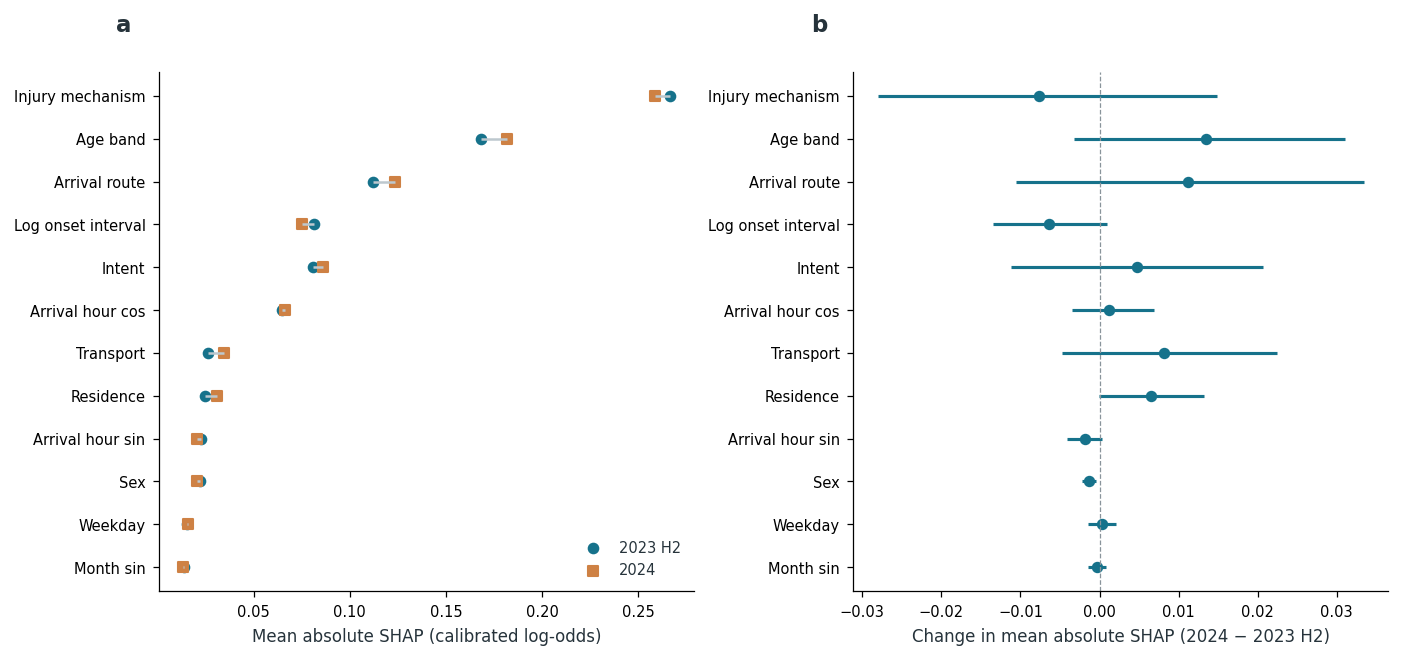

In [13]:
# 13. SHAP 결과가 특정 연도의 설명 표본에만 의존하는지 확인합니다.
from scipy.spatial.distance import jensenshannon
reference_ids=np.sort(np.random.default_rng(SEED+401).choice(cal,size=min(SHAP_N,len(cal)),replace=False))
reference_raw=cb.get_feature_importance(Pool(F.iloc[reference_ids][CORE],cat_features=[c for c in CORE if c in CAT]),
                                     type='ShapValues',thread_count=N_THREADS)
reference_shap=reference_raw[:,:-1]*a
reference_base=reference_raw[:,-1]*a+b
assert np.max(abs(expit(reference_base+reference_shap.sum(1))-calibrated(cb,calibrator,F.iloc[reference_ids][CORE])))<1e-8

def shap_bootstrap(values,idx,seed):
    codes,unique=pd.factorize(days.iloc[idx],sort=True)
    sums=np.zeros((len(unique),values.shape[1]))
    np.add.at(sums,codes,abs(values))
    counts=np.bincount(codes)
    draws=np.random.default_rng(seed).multinomial(len(unique),np.repeat(1/len(unique),len(unique)),size=499)
    return draws@sums/(draws@counts)[:,None]
reference_boot=shap_bootstrap(reference_shap,reference_ids,SEED+402)
test_boot=shap_bootstrap(shap_values,xai_ids,SEED+403)
lo,hi=np.quantile(test_boot-reference_boot,[.025,.975],axis=0)
stability=pd.DataFrame({'feature':CORE,'mean_abs_2023':abs(reference_shap).mean(0),'mean_abs_2024':abs(shap_values).mean(0),
                        'change_CI_low':lo,'change_CI_high':hi})
stability['change']=stability.mean_abs_2024-stability.mean_abs_2023
rho=float(spearmanr(stability.mean_abs_2023,stability.mean_abs_2024).statistic)
top23=set(stability.nlargest(5,'mean_abs_2023').feature)
top24=set(stability.nlargest(5,'mean_abs_2024').feature)
RUN['explanation_stability']={'rank_spearman':rho,'top5_overlap':len(top23 & top24),'reference_n':len(reference_ids),'test_n':len(xai_ids)}
record('28_explanation_stability',stability.sort_values('mean_abs_2023',ascending=False),'설명 분포의 연도 간 변화',show=False)

drift=[]
for col in CORE:
    ref=F.iloc[cal][col];new=F.iloc[test][col]
    if col not in CAT:
        finite=ref.dropna()
        edges=np.unique(np.r_[-np.inf,np.quantile(finite,np.linspace(0,1,9))[1:-1],np.inf])
        ref=pd.cut(ref,edges,include_lowest=True).astype(str)
        new=pd.cut(new,edges,include_lowest=True).astype(str)
    ref=ref.fillna('Unknown').astype(str);new=new.fillna('Unknown').astype(str)
    levels=sorted(set(ref)|set(new))
    p=ref.value_counts(normalize=True).reindex(levels,fill_value=0).to_numpy()
    q=new.value_counts(normalize=True).reindex(levels,fill_value=0).to_numpy()
    drift.append({'feature':col,'JS_distance':float(jensenshannon(p,q,base=2)),'TV_distance':float(.5*abs(p-q).sum())})
drift=pd.DataFrame(drift)
record('29_feature_drift',drift.sort_values('JS_distance',ascending=False),'2023년 하반기와 2024년 변수 분포 변화',show=False)
fig,axs=plt.subplots(1,2,figsize=(9.25,4.3),layout='constrained')
z=stability.sort_values('mean_abs_2023',ascending=False).head(12).iloc[::-1];pos=np.arange(len(z))
ax=axs[0]
ax.hlines(pos,z.mean_abs_2023,z.mean_abs_2024,color='#bdc8ce',lw=1.2)
ax.scatter(z.mean_abs_2023,pos,s=21,color=BLUE,label='2023 H2');ax.scatter(z.mean_abs_2024,pos,s=21,marker='s',color=ORANGE,label='2024')
ax.set_yticks(pos,z.feature);ax.set_xlabel('Mean absolute SHAP (calibrated log-odds)');ax.legend(loc='lower right');style(ax,'x');panel(ax,'a')
ax=axs[1];ax.hlines(pos,z.change_CI_low,z.change_CI_high,color=BLUE);ax.scatter(z.change,pos,color=BLUE,s=20)
ax.axvline(0,ls='--',lw=.6,color='#89949b');ax.set_yticks(pos,z.feature);ax.set_xlabel('Change in mean absolute SHAP (2024 − 2023 H2)');style(ax,'x');panel(ax,'b')
figure('Figure_10_explanation_stability',fig,'Figure 10. Explanation distributions under a fixed calibrated model. Intervals separately resample arrival dates in the two explanation samples. The displayed features are ranked by 2023 H2 importance. These intervals describe sampled explanations, not refitted-model uncertainty.')

## 13. 결과를 읽고 논문 질문으로 연결합니다
- 실험이 끝나면 아래 요약은 실제 계산된 수치로 채워집니다. 변수 제거·추가 실험의 방향과 구간을 보고 중심 질문을 정할 수 있습니다.
- 논문에서 보고할 항목은 표본의 추출 범위, 기록된 표적의 의미, 시간 분할, 시험 분모, 모델 선택 규칙, 보정, 주 통계 대조, 설명 단위와 한계입니다. 보고 항목 구성에는 TRIPOD+AI를 참고했습니다.
- 이 코드에서 생성된 결과는 후향적 기록 분석입니다. 제공 파일에는 활력징후·KTAS·진료결과·개인/병원 식별자가 없으므로 임상적 유용성, 전국 대표성, 외부기관 일반화의 주장은 추가 자료와 검증을 필요로 합니다.

In [14]:
# 14. 본문에 옮겨 쓸 때 수치와 분석 범위를 함께 볼 수 있도록 실제 결과를 요약합니다.
best=performance.sort_values(['AP','Brier'],ascending=[False,True]).iloc[0]
cb_row=performance.set_index('model').loc['CatBoost']
context_row=variant_rows.set_index('variant').loc['Plus full coding context']
context_ci=variant_intervals[(variant_intervals.variant.eq('Plus full coding context')) & variant_intervals.metric.eq('AP')].iloc[0]
main_contrast=comparisons[comparisons.comparator.eq('Logistic')].iloc[0]
findings=[
 f'분석 표본은 {len(F):,}건이며 기록된 비응급(N)은 {int(y.sum()):,}건({y.mean():.2%})입니다. 2024년 시험 표본은 {len(test):,}건입니다.',
 f'2024년 시험 AP가 가장 높은 주 비교 모델은 {best.model} ({best.AP:.3f})입니다. CatBoost의 AP는 {cb_row.AP:.3f}, AUROC는 {cb_row.AUROC:.3f}, Brier는 {cb_row.Brier:.4f}입니다.',
 f'CatBoost − 로지스틱 회귀의 Brier 차이는 {main_contrast.Brier_difference:+.5f}, 일자 블록 95% 구간은 [{main_contrast.Brier_CI_low:+.5f}, {main_contrast.Brier_CI_high:+.5f}], Holm 보정 p값은 {main_contrast.p_Holm:.4f}입니다.',
 f'기관 종별·증상 코드·일련번호를 모두 추가한 모델의 AP는 {context_row.AP:.3f}입니다. 기본 모델 대비 AP 차이 {context_ci.difference_from_core:+.3f}의 대응 95% 구간은 [{context_ci.CI_low:+.3f}, {context_ci.CI_high:+.3f}]입니다.',
 f'같은 모델의 2023년 하반기와 2024년 SHAP 중요도 순위 상관은 {rho:.3f}이고 상위 5개 변수 중 {len(top23 & top24)}개가 겹칩니다. SHAP 합으로 복원한 보정 확률의 최대 오차는 {max_error:.2e}입니다.',
 f'발병시각 1111의 대체 해석으로 파생변수가 바뀐 내원은 {int(changed.sum()):,}건입니다. 7일 초과 간격과 미상 간격의 분모는 시간 품질표에 기록했습니다.'
]
display(HTML('<div style="font-size:15px;line-height:1.7">'+''.join('<p>'+html.escape(v)+'</p>' for v in findings)+'</div>'))
questions=pd.DataFrame([
 ['시간적 일반화','과거 연도로 학습한 확률 예측이 2024년에도 유지되는가?','12–17, 20','Fig. 4–5, 7','등록된 표적과 표본의 범위'],
 ['기록 맥락의 영향','기관 종별·증상 코드·일련번호가 성능에 얼마나 기여하는가?','18–19, 22','Fig. 6–7','입력 완료 시점과 기관별 차이'],
 ['설명 안정성','입력 분포가 달라졌을 때 같은 모델의 설명 순위는 얼마나 유지되는가?','25–29','Fig. 8–10','SHAP의 조건부 연관성과 설명 표본 변동'],
 ['시간 기록의 불확실성','미상시각 해석과 발병 간격 처리에 결론이 민감한가?','03, 08, 21','Fig. 3','시각 반올림과 긴 간격의 의미']],
 columns=['research_angle','question','tables','figures','interpretation_scope'])
record('30_research_questions',questions,'논문 질문과 검증 근거',show=False)

## 14. 표·그림·HTML을 한 번에 저장합니다
- 10개 복합 그림을 **600 dpi PNG, PDF, SVG**로 저장합니다. 개별 그림에 사용한 수치와 검정표는 CSV로 제공합니다.
- `NEDIS_Report.html`을 열면 요약·그림·표·분석 조건을 오프라인으로 볼 수 있습니다. 표 검색창으로 변수나 모델을 찾을 수 있습니다.
- 개인별 행 자료와 증상 원문을 외부 API로 전송하는 단계가 없습니다. 기본 결과물은 집계표·그림·방법 설명이며 원본 엑셀은 ZIP에 다시 넣지 않습니다.
- 끝까지 실행된 파일 목록과 코드 환경은 `run_manifest.json`에서 확인할 수 있습니다. Colab 다운로드가 차단되면 왼쪽 파일 탭의 ZIP을 직접 내려받을 수 있습니다.

In [15]:
# 15. 재현 정보에는 입력 지문, 분할, 설정, 패키지 버전과 파일별 지문을 기록합니다.
from datetime import datetime,timezone
RUN.update({'seed':SEED,'figure_dpi':DPI,'bootstrap_draws':BOOTSTRAPS,'sign_flips':PERMUTATIONS,
 'python':platform.python_version(),'packages':{p:metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','openpyxl','catboost']},
 'completed_utc':datetime.now(timezone.utc).isoformat(),'elapsed_seconds':round(perf_counter()-START,2),
 'interpretation':['Selected Gyeonggi non-disease transported visits','Recorded PTMIEMSY label',
  'No national sampling weights in supplied workbook','No individual or hospital identifier',
  'Chronological 2024 test with arrival-date bootstrap','Conditional on the supplied retrospective sample']})
references=[
 ['NEDIS 응급표본자료 공개 안내','https://www.emergency.or.kr/bbs/data/2664/download/556','표본자료와 가중치의 활용 범위'],
 ['중앙응급의료센터 데이터 이용 안내','https://dw.nemc.or.kr/nemcMonitoring/data/user/DataUseInfoSub.do','자료원과 제공 절차'],
 ['Collins et al., TRIPOD+AI, BMJ, 2024','https://doi.org/10.1136/bmj-2023-078378','예측모델 연구의 자료·개발·검증 보고'],
 ['Guiding questions to avoid data leakage, Nature Methods, 2024','https://doi.org/10.1038/s41592-024-02362-y','분석단계의 정보 누수 점검'],
 ['Why do probabilistic clinical models fail to transport between sites, npj Digital Medicine, 2024','https://doi.org/10.1038/s41746-024-01037-4','진료·기록 환경과 확률 예측의 전이'],
 ['Prokhorenkova et al., CatBoost, NeurIPS, 2018','https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html','범주형 자료의 부스팅'],
 ['CatBoost ShapValues documentation','https://catboost.ai/docs/en/concepts/shap-values','모델 출력과 SHAP 합의 관계'],
 ['Nature research figure guide','https://research-figure-guide.nature.com/figures/','색상·가독성·벡터 출력 원칙']]
record('31_sources',pd.DataFrame(references,columns=['source','url','used_for']),'참고한 방법과 공식 자료',show=False)
RUN['files_before_manifest']={name:hashlib.sha256(path.read_bytes()).hexdigest() for name,path in ARTIFACTS.items()}
manifest=OUT/'run_manifest.json';manifest.write_text(json.dumps(RUN,ensure_ascii=False,indent=2),encoding='utf-8');ARTIFACTS[manifest.name]=manifest

# HTML은 이미지와 CSS를 모두 포함합니다. 별도 웹 서버나 로그인 없이 열 수 있습니다.
intro='<section id="results"><h2>실행 결과</h2>'+''.join('<p>'+html.escape(t)+'</p>' for t in findings)+'</section>'
fig_html='<section id="figures"><h2>출판용 그림</h2>'+''.join('<figure><img src="data:image/png;base64,'+data+'" alt="'+html.escape(caption)+'"><figcaption>'+html.escape(caption)+'</figcaption></figure>' for caption,data in FIGURES.values())+'</section>'
table_html='<section id="tables"><h2>표와 검정</h2><label>표 검색 <input id="table-search" type="search" placeholder="모델 또는 변수명"></label>'
for title,frame in TABLES.items():
    table_html+='<details open><summary>'+html.escape(title)+'</summary><div class="table-wrap">'+frame.round(5).to_html(index=False,border=0,escape=True)+'</div></details>'
table_html+='</section>'
method_text='경기 소재 응급기관의 질병 외 이송 내원에 대한 후향적 분석입니다. 표적은 기록된 PTMIEMSY=N입니다. 2020–2022년 후보 학습, 2023년 상반기 설정 선택 후 재학습, 2023년 하반기 보정, 2024년 최종 시험의 시간 순서를 유지했습니다. 주 성능 구간은 시험 일자 재추출에 조건부입니다. 개인·병원 식별자 및 표본 가중치가 없어 전국 대표성, 병원 군집, 반복환자 의존성을 추정하지 않았습니다.'
methods='<section id="methods"><h2>분석 조건과 재현</h2><p>'+html.escape(method_text)+'</p><pre>'+html.escape(manifest.read_text())+'</pre><h3>참고 자료</h3><ul>'+''.join('<li><a href="'+url+'">'+html.escape(name)+'</a> — '+html.escape(purpose)+'</li>' for name,url,purpose in references)+'</ul></section>'
css='''body{margin:0;background:#f7f9fa;color:#26333b;font:15px/1.65 system-ui,sans-serif}header,main{max-width:1120px;margin:auto;padding:26px}header{padding-bottom:8px}h1{font-size:29px;line-height:1.25;margin:4px 0 12px}h2{font-size:22px;margin-top:32px}h3{font-size:18px}nav{display:flex;gap:20px;flex-wrap:wrap;background:white;border-bottom:1px solid #dce5e9;padding:12px 0}a{color:#176b86;text-decoration:none}a:hover{text-decoration:underline}figure,details,#results,#methods{background:white;border:1px solid #e0e7ea;border-radius:8px;padding:18px;margin:18px 0}figure img{width:100%;height:auto}figure{overflow:auto}figcaption{font-size:13px;color:#53616b;margin-top:12px}summary{cursor:pointer;font-weight:600}.table-wrap{overflow-x:auto}table{font-size:12px;border-collapse:collapse;white-space:nowrap;min-width:65%}td,th{padding:7px 10px;text-align:left;border-bottom:1px solid #e4ebef}th{background:#eff5f7}input{font:inherit;border:1px solid #aabcc5;padding:7px 12px;border-radius:5px;width:260px;max-width:80%}pre{font:12px/1.5 monospace;white-space:pre-wrap;overflow-wrap:anywhere}p{margin:.65em 0}@media print{body{background:white}nav,#table-search,label{display:none}figure{break-inside:avoid;border:0}}'''
script="document.getElementById('table-search').addEventListener('input',function(){const q=this.value.toLowerCase();document.querySelectorAll('#tables details').forEach(d=>{d.style.display=d.textContent.toLowerCase().includes(q)?'':'none';});});"
page='<!doctype html><html lang="ko"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>NEDIS · EDA and XAI</title><style>'+css+'</style></head><body><header><h1>NEDIS 2020–2024<br>시간 변화와 설명가능 예측</h1><p>'+f'분석 {len(F):,}건 · 최종 시험 {len(test):,}건 · 그림 10개 · 600 dpi'+'</p><nav><a href="#results">실행 결과</a><a href="#figures">그림</a><a href="#tables">표 검색</a><a href="#methods">방법·출처</a></nav></header><main>'+intro+fig_html+table_html+methods+'</main><script>'+script+'</script></body></html>'
report=OUT/'NEDIS_Report.html';report.write_text(page,encoding='utf-8');ARTIFACTS[report.name]=report
archive=Path('NEDIS_Results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for name,path in ARTIFACTS.items():z.write(path,arcname=name)
with zipfile.ZipFile(archive) as z:assert z.testzip() is None
print(f'완료 · 결과 파일 {len(ARTIFACTS)}개 · 그림 {len(FIGURES)}개 · 실행 {RUN["elapsed_seconds"]:.0f}초')
print('NEDIS_Report.html을 열면 계산된 값과 그림을 함께 볼 수 있습니다.')
display(HTML('<a href="'+html.escape(archive.name)+'" download>결과 ZIP 다운로드</a>'))
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files=None
if AUTO_DOWNLOAD and colab_files is not None:
    colab_files.download(str(archive))

완료 · 결과 파일 63개 · 그림 10개 · 실행 289초
NEDIS_Report.html을 열면 계산된 값과 그림을 함께 볼 수 있습니다.
